# 🚲 SmartRebalance ZGZ · Estudio de Estaciones Saturadas (> 80 %)
## Análisis de subestimación en picos de llenado y soporte a la toma de decisiones

**Dataset de origen:** Capa Gold — Instantánea congelada (`data/gold_snapshot_ml_20261122/`)  
**Modelo auditado:** Modelo Campeón `LightGBM (Optuna)` en los tres horizontes tácticos ($h \in \{+1\text{ h}, +2\text{ h}, +3\text{ h}\}$)  
**Umbral operativo de referencia:** Riesgo de saturación (`OCCUPANCY_HIGH_THRESHOLD = 0.80`)

---

### Contexto y motivación del estudio

En la evaluación ciega fuera de entrenamiento (`df_test`, 114.816 registros y 276 estaciones), el modelo campeón **LightGBM (Optuna)** ofrece un rendimiento sólido en error continuo global y en la detección de estaciones en riesgo de vaciado ($< 20\%$), pero muestra una **degradación pronunciada al anticipar estaciones saturadas ($> 80\%$)**, donde el **F1 Saturada** desciende de **0,3888** ($+1\text{ h}$) a **0,2348** ($+2\text{ h}$) y **0,1702** ($+3\text{ h}$).

Como evidenció el caso de estudio de la sección 10.4 (*`23-Ribera. Azud`*, 2026-11-19, horizonte $+2\text{ h}$), el regresor suele seguir correctamente la tendencia de llenado, pero **suaviza los picos extremos hacia la media** al optimizar el error global. En la práctica, esto provoca que numerosas predicciones se queden por debajo del umbral de alarma del **80 %** cuando la estación alcanza ocupaciones reales del 90 %–100 %, impidiendo que el optimizador de rutas active las órdenes de retirada (*PICKUP*).

### Objetivo del cuaderno

Ampliar el análisis a **los tres horizontes ($+1\text{ h}, +2\text{ h}, +3\text{ h}$)** y a **un conjunto amplio de estaciones que se saturan en `Test`** para:
1. Cuantificar con precisión cuánto se quedan cortas las predicciones de LightGBM cuando la ocupación real supera el 80 %.
2. Evaluar si el problema es generalizado en la red o se concentra en determinados polos de atracción y franjas horarias.
3. Disponer de evidencia cuantitativa y visual para decidir la estrategia correctora más adecuada (ajuste de umbral de alarma / *threshold tuning*, regresión por cuantiles, ponderación de muestras o clasificador binario auxiliar de saturación).

In [1]:
# ==============================================================================
# BLOQUE PREVIO: ENTORNO, DATOS, FEATURES, MODELO CAMPEÓN, df_eval Y FUNCIONES
# ==============================================================================
from pathlib import Path
import sys
import time
import warnings

from IPython.display import display
import joblib
import lightgbm as lgb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    f1_score,
    mean_absolute_error,
    precision_score,
    r2_score,
    recall_score,
    root_mean_squared_error,
)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------------------
# 1. RUTAS Y CONSTANTES DEL PROYECTO
# ------------------------------------------------------------------------------
ROOT_DIR = Path.cwd().resolve()
if ROOT_DIR.name == "notebooks":
    ROOT_DIR = ROOT_DIR.parent

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

DATA_DIR = ROOT_DIR / "data"
GOLD_SNAPSHOT_DIR = DATA_DIR / "gold_snapshot_ml_20261122"
MODEL_DIR = ROOT_DIR / "models" / "lgbm_v1"

PATH_DF_GOLD = GOLD_SNAPSHOT_DIR / "df_gold.parquet"
PATH_DIM_STATIONS = GOLD_SNAPSHOT_DIR / "dim_stations.parquet"
PATH_DIM_CALENDAR = GOLD_SNAPSHOT_DIR / "dim_calendar.parquet"

# Cambiar a True si los .joblib en models/lgbm_v1 corresponden a este mismo snapshot
USE_SAVED_MODELS = False

RANDOM_STATE = 42
FREQ_MINUTES = 10
HORIZONS_HOURS = [1, 2, 3]
TARGET_COLS = [f"target_occ_{h}h" for h in HORIZONS_HOURS]

OCCUPANCY_LOW_THRESHOLD = 0.20
OCCUPANCY_HIGH_THRESHOLD = 0.80

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid")

# Hiperparámetros óptimos obtenidos con Optuna en modelado_predictivo.ipynb
BEST_PARAMS_OPTUNA = {
    1: {
        "learning_rate": 0.032580045769112206,
        "num_leaves": 105,
        "max_depth": 12,
        "min_child_samples": 95,
        "subsample": 0.6883385751926184,
        "colsample_bytree": 0.6611367492367999,
        "reg_alpha": 0.6145982202528154,
        "reg_lambda": 0.006573856567096192,
    },
    2: {
        "learning_rate": 0.03361441955478077,
        "num_leaves": 123,
        "max_depth": 10,
        "min_child_samples": 80,
        "subsample": 0.7046065241548528,
        "colsample_bytree": 0.7045980821176709,
        "reg_alpha": 0.0017073967431528124,
        "reg_lambda": 2.9154431891537547,
    },
    3: {
        "learning_rate": 0.02015369312797273,
        "num_leaves": 110,
        "max_depth": 10,
        "min_child_samples": 93,
        "subsample": 0.919944621340081,
        "colsample_bytree": 0.6759156281069316,
        "reg_alpha": 0.02715581955282941,
        "reg_lambda": 0.0029072088906598446,
    },
}

BASE_FEATURES = [
    "occupancy_pct",
    "bikes_available",
    "anchors_free",
    "capacity",
    "disabled_units",
    "station_id_cat",
    "latitude",
    "longitude",
    "occ_lag_10m",
    "occ_lag_30m",
    "occ_lag_1h",
    "occ_lag_24h",
    "occ_lag_7d",
    "delta_occ_30m",
    "delta_occ_1h",
    "rolling_std_1h",
    "causal_hist_occ_mean",
    "occ_diff_vs_hist_mean",
    "delta_bikes_10m",
    "is_logistic_jump",
    "logistic_jumps_last_1h",
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "is_weekend_flag",
    "is_holiday",
]


def get_features_for_horizon(horizon_h: int) -> list[str]:
    return BASE_FEATURES + [
        f"target_hour_sin_{horizon_h}h",
        f"target_hour_cos_{horizon_h}h",
        f"target_is_weekend_{horizon_h}h",
    ]


# ------------------------------------------------------------------------------
# 2. CARGA DE CAPA GOLD Y CONSTRUCCIÓN DE TARGETS MULTI-HORIZONTE
# ------------------------------------------------------------------------------
t_global = time.time()
df_gold = pd.read_parquet(PATH_DF_GOLD)
df_stations = pd.read_parquet(PATH_DIM_STATIONS)
df_calendar = pd.read_parquet(PATH_DIM_CALENDAR)

station_static_cols = ["name", "latitude", "longitude", "capacity"]
df_gold = (
    df_gold.drop(columns=station_static_cols, errors="ignore")
    .merge(
        df_stations[["station_id"] + station_static_cols],
        on="station_id",
        how="left",
        validate="m:1",
    )
    .sort_values(["station_id", "timestamp"])
    .reset_index(drop=True)
)

df_gold["disabled_units"] = (
    df_gold["capacity"] - df_gold["bikes_available"] - df_gold["anchors_free"]
).clip(lower=0)

df_model = (
    df_gold[df_gold["is_estimated"] == 0]
    .sort_values(["timestamp", "station_id"])
    .reset_index(drop=True)
    .copy()
)

future_truth = df_model[["station_id", "timestamp", "occupancy_pct", "bikes_available"]].copy()

for h in HORIZONS_HOURS:
    target_ts_col = f"_target_ts_{h}h"
    df_model[target_ts_col] = df_model["timestamp"] + pd.Timedelta(hours=h)

    df_model = pd.merge_asof(
        df_model.sort_values(target_ts_col),
        future_truth.rename(
            columns={
                "timestamp": "_future_ts",
                "occupancy_pct": f"target_occ_{h}h",
                "bikes_available": f"target_bikes_{h}h",
            }
        ),
        left_on=target_ts_col,
        right_on="_future_ts",
        by="station_id",
        direction="nearest",
        tolerance=pd.Timedelta(minutes=FREQ_MINUTES),
    )
    df_model.drop(columns=[target_ts_col, "_future_ts"], inplace=True)

df_model = df_model.sort_values(["station_id", "timestamp"]).reset_index(drop=True)


# ------------------------------------------------------------------------------
# 3. FEATURE ENGINEERING ANTI-LEAKAGE
# ------------------------------------------------------------------------------
def build_feature_matrix(
    df: pd.DataFrame,
    horizons: list[int] = [1, 2, 3],
    df_cal: pd.DataFrame | None = None,
) -> pd.DataFrame:
    out = df.sort_values(["station_id", "timestamp"]).reset_index(drop=True).copy()
    ref = (
        out[["station_id", "timestamp", "occupancy_pct"]]
        .sort_values("timestamp")
        .reset_index(drop=True)
        .copy()
    )

    lag_specs = [
        ("occ_lag_10m", pd.Timedelta(minutes=10), pd.Timedelta(minutes=5)),
        ("occ_lag_30m", pd.Timedelta(minutes=30), pd.Timedelta(minutes=10)),
        ("occ_lag_1h", pd.Timedelta(hours=1), pd.Timedelta(minutes=10)),
        ("occ_lag_24h", pd.Timedelta(hours=24), pd.Timedelta(minutes=15)),
        ("occ_lag_7d", pd.Timedelta(days=7), pd.Timedelta(minutes=15)),
    ]
    for col_name, offset, tol in lag_specs:
        out["_lookup_ts"] = out["timestamp"] - offset
        out = pd.merge_asof(
            out.sort_values("_lookup_ts"),
            ref.rename(columns={"timestamp": "_ref_ts", "occupancy_pct": col_name}),
            left_on="_lookup_ts",
            right_on="_ref_ts",
            by="station_id",
            direction="nearest",
            tolerance=tol,
        )
        out.drop(columns=["_lookup_ts", "_ref_ts"], inplace=True)

    out = out.sort_values(["station_id", "timestamp"]).reset_index(drop=True)

    out["delta_occ_30m"] = out["occupancy_pct"] - out["occ_lag_30m"]
    out["delta_occ_1h"] = out["occupancy_pct"] - out["occ_lag_1h"]
    out["rolling_std_1h"] = (
        out.groupby("station_id")["occupancy_pct"]
        .transform(lambda s: s.rolling(window=6, min_periods=2).std())
        .fillna(0.0)
    )

    dt_min = out.groupby("station_id")["timestamp"].diff().dt.total_seconds() / 60.0
    delta_bikes = out.groupby("station_id")["bikes_available"].diff()
    out["delta_bikes_10m"] = np.where(dt_min.between(8, 12), delta_bikes, 0.0)
    out["is_logistic_jump"] = (out["delta_bikes_10m"].abs() >= 8).astype(int)
    out["logistic_jumps_last_1h"] = (
        out.groupby("station_id")["is_logistic_jump"]
        .transform(lambda s: s.rolling(window=6, min_periods=1).sum())
    )

    # Perfil histórico causal por (estación, tipo de día, hora)
    out["_date_only"] = out["timestamp"].dt.floor("D")
    grp_cols = ["station_id", "day_type_effective", "hour"]
    daily_slot = (
        out.groupby(grp_cols + ["_date_only"], as_index=False)
        .agg(_day_occ_sum=("occupancy_pct", "sum"), _day_occ_cnt=("occupancy_pct", "count"))
        .sort_values(grp_cols + ["_date_only"])
    )
    daily_slot["_cum_sum_prev"] = (
        daily_slot.groupby(grp_cols)["_day_occ_sum"].cumsum() - daily_slot["_day_occ_sum"]
    )
    daily_slot["_cum_cnt_prev"] = (
        daily_slot.groupby(grp_cols)["_day_occ_cnt"].cumsum() - daily_slot["_day_occ_cnt"]
    )
    daily_slot["causal_hist_occ_mean"] = np.where(
        daily_slot["_cum_cnt_prev"] > 0,
        daily_slot["_cum_sum_prev"] / daily_slot["_cum_cnt_prev"],
        np.nan,
    )
    out = out.merge(
        daily_slot[grp_cols + ["_date_only", "causal_hist_occ_mean"]],
        on=grp_cols + ["_date_only"],
        how="left",
        validate="m:1",
    )
    out["occ_diff_vs_hist_mean"] = out["occupancy_pct"] - out["causal_hist_occ_mean"]
    out.drop(columns=["_date_only"], inplace=True)

    # Calendario cíclico actual y por horizonte
    out["hour_sin"] = np.sin(2 * np.pi * out["hour"] / 24.0)
    out["hour_cos"] = np.cos(2 * np.pi * out["hour"] / 24.0)
    dow = out["timestamp"].dt.dayofweek
    out["dow_sin"] = np.sin(2 * np.pi * dow / 7.0)
    out["dow_cos"] = np.cos(2 * np.pi * dow / 7.0)
    out["is_weekend_flag"] = (out["day_type_effective"] == "WEEKEND").astype(int)

    weekend_date_keys = None
    if df_cal is not None and {"date_key", "day_type_effective"}.issubset(df_cal.columns):
        weekend_date_keys = set(
            df_cal.loc[df_cal["day_type_effective"] == "WEEKEND", "date_key"].astype(int)
        )

    for h in horizons:
        future_ts = out["timestamp"] + pd.Timedelta(hours=h)
        f_hour = future_ts.dt.hour
        f_dow = future_ts.dt.dayofweek
        out[f"target_hour_sin_{h}h"] = np.sin(2 * np.pi * f_hour / 24.0)
        out[f"target_hour_cos_{h}h"] = np.cos(2 * np.pi * f_hour / 24.0)
        if weekend_date_keys is not None:
            f_date_key = future_ts.dt.strftime("%Y%m%d").astype(int)
            out[f"target_is_weekend_{h}h"] = np.where(
                f_date_key.isin(weekend_date_keys) | (f_dow >= 5), 1, 0
            )
        else:
            out[f"target_is_weekend_{h}h"] = (f_dow >= 5).astype(int)

    out["station_id_cat"] = out["station_id"].astype("category")
    return out


df_features = build_feature_matrix(df_model, horizons=HORIZONS_HOURS, df_cal=df_calendar)

# ------------------------------------------------------------------------------
# 4. PARTICIÓN TEMPORAL ESTRICTA (70% / 15% / 15% CON EMBARGO DE 3H)
# ------------------------------------------------------------------------------
df_clean = (
    df_features.dropna(subset=TARGET_COLS)
    .sort_values(["timestamp", "station_id"])
    .reset_index(drop=True)
    .copy()
)

unique_ts = np.sort(df_clean["timestamp"].unique())
n_ts = len(unique_ts)
embargo = pd.Timedelta(hours=max(HORIZONS_HOURS))

train_cutoff_ts = pd.Timestamp(unique_ts[int(n_ts * 0.70)])
val_cutoff_ts = pd.Timestamp(unique_ts[int(n_ts * 0.85)])

df_train = df_clean[df_clean["timestamp"] <= (train_cutoff_ts - embargo)].reset_index(drop=True)
df_val = df_clean[
    (df_clean["timestamp"] > train_cutoff_ts)
    & (df_clean["timestamp"] <= (val_cutoff_ts - embargo))
].reset_index(drop=True)
df_test = df_clean[df_clean["timestamp"] > val_cutoff_ts].reset_index(drop=True)

train_categories = df_train["station_id_cat"].cat.categories


def align_tree_features(df_part: pd.DataFrame, feature_cols: list[str]) -> pd.DataFrame:
    X = df_part[feature_cols].copy()
    X["station_id_cat"] = pd.Categorical(X["station_id_cat"], categories=train_categories)
    return X


# ------------------------------------------------------------------------------
# 5. CARGA O ENTRENAMIENTO DEL MODELO CAMPEÓN Y GENERACIÓN DE df_eval
# ------------------------------------------------------------------------------
best_lgbm_models = {}

eval_base_cols = [
    "station_id",
    "name",
    "capacity",
    "latitude",
    "longitude",
    "timestamp",
    "date",
    "hour",
    "day_type_effective",
    "is_holiday",
    "occupancy_pct",
    "bikes_available",
    "anchors_free",
    "disabled_units",
]
df_eval = df_test[eval_base_cols].copy()

resumen_test = []

for h in HORIZONS_HOURS:
    target_col = f"target_occ_{h}h"
    feat_cols = get_features_for_horizon(h)

    X_tr = align_tree_features(df_train, feat_cols)
    X_va = align_tree_features(df_val, feat_cols)
    X_te = align_tree_features(df_test, feat_cols)

    y_tr = df_train[target_col]
    y_va = df_val[target_col]
    y_te = df_test[target_col].to_numpy(dtype=float)

    model_path = MODEL_DIR / f"lgbm_{h}h.joblib"
    if USE_SAVED_MODELS and model_path.exists():
        model = joblib.load(model_path)
    else:
        params = {
            "objective": "regression",
            "metric": "mae",
            "n_estimators": 1000,
            "subsample_freq": 1,
            "subsample_for_bin": 50000,
            "random_state": RANDOM_STATE,
            "n_jobs": -1,
            "verbose": -1,
            **BEST_PARAMS_OPTUNA[h],
        }
        model = lgb.LGBMRegressor(**params)
        model.fit(
            X_tr,
            y_tr,
            eval_set=[(X_va, y_va)],
            callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)],
        )

    best_lgbm_models[h] = model

    pred_lgbm = np.clip(model.predict(X_te), 0.0, 1.0)
    pred_naive = df_test["occupancy_pct"].to_numpy(dtype=float)

    df_eval[f"target_ts_{h}h"] = df_eval["timestamp"] + pd.Timedelta(hours=h)
    df_eval[f"target_occ_{h}h"] = y_te
    df_eval[f"pred_lgbm_{h}h"] = pred_lgbm
    df_eval[f"pred_naive_{h}h"] = pred_naive
    df_eval[f"error_lgbm_{h}h"] = pred_lgbm - y_te  # Negativo = subestimación
    df_eval[f"abs_error_lgbm_{h}h"] = np.abs(pred_lgbm - y_te)
    df_eval[f"real_sat_{h}h"] = (y_te > OCCUPANCY_HIGH_THRESHOLD).astype(int)
    df_eval[f"pred_sat_{h}h"] = (pred_lgbm > OCCUPANCY_HIGH_THRESHOLD).astype(int)

    real_sat = df_eval[f"real_sat_{h}h"]
    pred_sat = df_eval[f"pred_sat_{h}h"]
    resumen_test.append({
        "Horizonte": f"+{h}h",
        "MAE": round(mean_absolute_error(y_te, pred_lgbm), 4),
        "RMSE": round(root_mean_squared_error(y_te, pred_lgbm), 4),
        "R2": round(r2_score(y_te, pred_lgbm), 4),
        "Casos Sat (>80%)": int(real_sat.sum()),
        "Detectados (>80%)": int(((real_sat == 1) & (pred_sat == 1)).sum()),
        "Precision Sat": round(precision_score(real_sat, pred_sat, zero_division=0), 4),
        "Recall Sat": round(recall_score(real_sat, pred_sat, zero_division=0), 4),
        "F1 Saturada": round(f1_score(real_sat, pred_sat, zero_division=0), 4),
    })


# ------------------------------------------------------------------------------
# 6. FUNCIONES AUXILIARES DE VISUALIZACIÓN Y MÉTRICAS (SECCIONES 2 Y 3)
# ------------------------------------------------------------------------------
def plot_estacion_saturada_multihorizonte(
    df_eval: pd.DataFrame,
    station_id: int,
    fecha_objetivo: str | None = None,
    legend_loc: str = "lower right",
) -> None:
    """Pinta la curva real vs. LightGBM y Naive en +1h, +2h y +3h apilados verticalmente."""
    df_st = df_eval[df_eval["station_id"] == station_id].copy()
    station_name = df_st["name"].iloc[0]

    if fecha_objetivo is None:
        df_st["_fecha_2h"] = df_st["target_ts_2h"].dt.strftime("%Y-%m-%d")
        fecha_objetivo = (
            df_st.groupby("_fecha_2h")["real_sat_2h"]
            .sum()
            .sort_values(ascending=False)
            .index[0]
        )

    fig, axes = plt.subplots(3, 1, figsize=(15, 13.5), sharey=True)

    for idx, h in enumerate(HORIZONS_HOURS):
        ax = axes[idx]
        ts_col = f"target_ts_{h}h"
        real_col = f"target_occ_{h}h"
        lgbm_col = f"pred_lgbm_{h}h"
        naive_col = f"pred_naive_{h}h"

        sub = (
            df_st[df_st[ts_col].dt.strftime("%Y-%m-%d") == fecha_objetivo]
            .sort_values(ts_col)
            .copy()
        )

        ax.plot(
            sub[ts_col],
            sub[real_col],
            color="#1b263b",
            linewidth=2.2,
            label="Ocupación Real Observada",
        )
        ax.plot(
            sub[ts_col],
            sub[lgbm_col],
            color="#e67e22",
            linewidth=2.1,
            label=f"Predicción LightGBM (+{h}h)",
        )
        ax.plot(
            sub[ts_col],
            sub[naive_col],
            color="#8d99ae",
            linestyle="--",
            linewidth=1.4,
            label=f"Baseline Persistencia / Naive (+{h}h)",
        )
        ax.axhline(
            OCCUPANCY_HIGH_THRESHOLD,
            color="#c0392b",
            linestyle=":",
            linewidth=1.5,
            label="Umbral de Saturación (80%)",
        )

        # Franjas sin huecos: Real (fondo morado) + Predicción (rayado naranja encima)
        real_sat_mask = sub[real_col] > OCCUPANCY_HIGH_THRESHOLD
        pred_sat_mask = sub[lgbm_col] > OCCUPANCY_HIGH_THRESHOLD

        ax.fill_between(
            sub[ts_col],
            OCCUPANCY_HIGH_THRESHOLD,
            np.where(real_sat_mask, 1.02, OCCUPANCY_HIGH_THRESHOLD),
            step="mid",
            color="#8e44ad",
            alpha=0.18,
            linewidth=0.0,
            label="Franja real saturada (>80%)",
        )
        ax.fill_between(
            sub[ts_col],
            OCCUPANCY_HIGH_THRESHOLD,
            np.where(pred_sat_mask, 1.02, OCCUPANCY_HIGH_THRESHOLD),
            step="mid",
            facecolor="none",
            edgecolor="#e67e22",
            hatch="///",
            linewidth=0.0,
            alpha=0.75,
            label="Franja predicha saturada (>80%)",
        )

        n_real_sat = int(real_sat_mask.sum())
        n_det_sat = int((real_sat_mask & pred_sat_mask).sum())
        n_fp_sat = int((~real_sat_mask & pred_sat_mask).sum())
        mae_dia = mean_absolute_error(sub[real_col], sub[lgbm_col])

        ax.set_title(
            f"Caso de Estudio en Estación Saturada: [{station_id}] {station_name} "
            f"({fecha_objetivo}) · Horizonte +{h}h  |  "
            f"Aciertos: {n_det_sat}/{n_real_sat}  |  FP: {n_fp_sat}  |  MAE día: {mae_dia:.4f}",
            fontsize=11.2,
        )
        ax.set_xlabel(f"Hora objetivo (t + {h}h)")
        ax.set_ylabel("Ocupación de la estación")
        ax.set_ylim(-0.02, 1.05)
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
        ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=sub[ts_col].dt.tz))
        ax.legend(loc=legend_loc, ncol=2, fontsize=9, framealpha=0.92)

    plt.tight_layout()
    plt.show()


def resumen_saturacion_estacion(
    df_eval: pd.DataFrame,
    station_id: int,
    fecha_objetivo: str | None = None,
) -> pd.DataFrame:
    """Genera la tabla resumen por horizonte (+1h, +2h, +3h) en minutos y porcentajes."""
    df_st = df_eval[df_eval["station_id"] == station_id].copy()
    station_name = df_st["name"].iloc[0]

    if fecha_objetivo is None:
        df_st["_fecha_2h"] = df_st["target_ts_2h"].dt.strftime("%Y-%m-%d")
        fecha_objetivo = (
            df_st.groupby("_fecha_2h")["real_sat_2h"]
            .sum()
            .sort_values(ascending=False)
            .index[0]
        )

    filas = []
    for h in HORIZONS_HOURS:
        ts_col = f"target_ts_{h}h"
        real_col = f"target_occ_{h}h"
        lgbm_col = f"pred_lgbm_{h}h"

        sub = df_st[df_st[ts_col].dt.strftime("%Y-%m-%d") == fecha_objetivo]

        real_sat = sub[real_col] > OCCUPANCY_HIGH_THRESHOLD
        pred_sat = sub[lgbm_col] > OCCUPANCY_HIGH_THRESHOLD

        n_real_sat = int(real_sat.sum())
        n_pred_sat = int(pred_sat.sum())
        tp = int((real_sat & pred_sat).sum())
        fn = int((real_sat & ~pred_sat).sum())
        fp = int((~real_sat & pred_sat).sum())

        pct_real_detectado = (tp / n_real_sat * 100) if n_real_sat > 0 else 0.0
        pct_fp_sobre_alertas = (fp / n_pred_sat * 100) if n_pred_sat > 0 else 0.0
        occ_real_media_fp_pct = (
            sub.loc[(~real_sat & pred_sat), real_col].mean() * 100 if fp > 0 else np.nan
        )

        filas.append({
            "Horizonte": f"+{h}h",
            "Real Sat. >80% [min]": n_real_sat * FREQ_MINUTES,
            "Aciertos (TP) [min]": tp * FREQ_MINUTES,
            "No Detectados (FN) [min]": fn * FREQ_MINUTES,
            "Real Sat. Predicho [%]": round(pct_real_detectado, 2),
            "Pred. sin Sat. Real (FP) [min]": fp * FREQ_MINUTES,
            "FP sobre Alertas [%]": round(pct_fp_sobre_alertas, 2),
            "Occ. Real Media en FP [%]": round(occ_real_media_fp_pct, 2)
            if pd.notna(occ_real_media_fp_pct)
            else np.nan,
        })

    df_res = pd.DataFrame(filas).set_index("Horizonte")

    print(f"--- RESUMEN DE SATURACIÓN: [{station_id}] {station_name} ({fecha_objetivo}) ---")
    print("Leyenda de abreviaturas:")
    print("  • Sat. : Saturación (ocupación > 80 %) | Occ. : Ocupación real de la estación")
    print("  • TP   : Verdadero Positivo  -> Real > 80 % y el modelo SÍ lo predijo > 80 % (acierto)")
    print("  • FN   : Falso Negativo      -> Real > 80 % pero el modelo se quedó <= 80 % (fallo crítico)")
    print("  • FP   : Falso Positivo      -> El modelo predijo > 80 % pero la real fue <= 80 % (falsa alarma)\n")

    display(
        df_res.style.format(
            {
                "Real Sat. >80% [min]": "{:.0f}",
                "Aciertos (TP) [min]": "{:.0f}",
                "No Detectados (FN) [min]": "{:.0f}",
                "Real Sat. Predicho [%]": "{:.2f}",
                "Pred. sin Sat. Real (FP) [min]": "{:.0f}",
                "FP sobre Alertas [%]": "{:.2f}",
                "Occ. Real Media en FP [%]": "{:.2f}",
            },
            na_rep="-",
        )
    )
    return df_res


def _fecha_max_alertas_predichas(df_eval: pd.DataFrame, station_id: int) -> str:
    """Devuelve el día de Test con más alertas de saturación predichas (>80 %) en +1h."""
    df_st = df_eval[df_eval["station_id"] == station_id].copy()
    df_st["_fecha_1h"] = df_st["target_ts_1h"].dt.strftime("%Y-%m-%d")
    df_st["_pred_sat_1h"] = df_st["pred_lgbm_1h"] > OCCUPANCY_HIGH_THRESHOLD
    return (
        df_st.groupby("_fecha_1h")["_pred_sat_1h"]
        .sum()
        .sort_values(ascending=False)
        .index[0]
    )


def plot_estacion_pred_multihorizonte(
    df_eval: pd.DataFrame,
    station_id: int,
    legend_loc: str = "lower right",
) -> None:
    """Gráfica multi-horizonte fijando el día de Test con más alertas predichas (Sección 3)."""
    fecha = _fecha_max_alertas_predichas(df_eval, station_id)
    plot_estacion_saturada_multihorizonte(
        df_eval,
        station_id=station_id,
        fecha_objetivo=fecha,
        legend_loc=legend_loc,
    )


def resumen_saturacion_pred_estacion(
    df_eval: pd.DataFrame,
    station_id: int,
) -> pd.DataFrame:
    """Tabla resumen multi-horizonte fijando el día de Test con más alertas predichas (Sección 3)."""
    fecha = _fecha_max_alertas_predichas(df_eval, station_id)
    return resumen_saturacion_estacion(
        df_eval,
        station_id=station_id,
        fecha_objetivo=fecha,
    )


print(f"[OK] Entorno, df_eval y funciones listos en {time.time() - t_global:.1f}s")
print(f"     Registros en Test (df_eval): {len(df_eval):,} | Estaciones: {df_eval['station_id'].nunique()}")
print(f"     Rango Test                 : {df_eval['timestamp'].min()} --> {df_eval['timestamp'].max()}\n")
print("--- VERIFICACIÓN DE MÉTRICAS EN TEST (LIGHTGBM OPTUNA) ---")
display(pd.DataFrame(resumen_test))

[OK] Entorno, df_eval y funciones listos en 152.6s
     Registros en Test (df_eval): 114,816 | Estaciones: 276
     Rango Test                 : 2026-11-18 19:39:56+01:00 --> 2026-11-22 14:39:58+01:00

--- VERIFICACIÓN DE MÉTRICAS EN TEST (LIGHTGBM OPTUNA) ---


,Horizonte,MAE,RMSE,R2,Casos Sat (>80%),Detectados (>80%),Precision Sat,Recall Sat,F1 Saturada
0,+1h,0.0938,0.1335,0.7333,5230,1457,0.6436,0.2786,0.3888
1,+2h,0.1190,0.1624,0.6058,5234,778,0.5589,0.1486,0.2348
2,+3h,0.1318,0.1755,0.5383,5199,524,0.5464,0.1008,0.1702


---
## 1. Ranking Top 10 Estaciones Saturadas: Real vs. Predicción (+1h, +2h, +3h)

En esta sección comparamos las **10 estaciones con mayor número de registros saturados ($> 80\%$)** en el conjunto de `Test` frente a las **10 estaciones que el modelo `LightGBM (Optuna)` predice con mayor frecuencia por encima del umbral del 80 %**.

Para cada horizonte táctico ($h \in \{+1\text{ h}, +2\text{ h}, +3\text{ h}\}$) se muestran tres tablas:
1. **Top 10 Real:** Estaciones con más episodios reales de saturación en `Test`.
2. **Top 10 Predicho:** Estaciones con más alertas de saturación disparadas por el modelo.
3. **Tabla Comparativa:** Contraste posición a posición entre el ranking real y el predicho, indicando si hay coincidencia exacta en el puesto y cuántas posiciones difiere la estación real respecto a su ubicación en el ranking predicho.

In [2]:
# ==============================================================================
# 1.1. TOP 10 ESTACIONES SATURADAS: REAL VS. PREDICHO Y COMPARATIVA DE POSICIONES
# ==============================================================================
TOP_N = 10

for h in HORIZONS_HOURS:
    col_real_sat = f"real_sat_{h}h"
    col_pred_sat = f"pred_sat_{h}h"
    col_real_occ = f"target_occ_{h}h"
    col_pred_occ = f"pred_lgbm_{h}h"

    print("=" * 95)
    print(f"HORIZONTE +{h}H · RANKING TOP {TOP_N} ESTACIONES SATURADAS (> 80 %)")
    print("=" * 95)

    # Agregación por estación para el horizonte h
    resumen_est = (
        df_eval.groupby(["station_id", "name"], as_index=False)
        .agg(
            casos_real_sat=(col_real_sat, "sum"),
            pct_real_sat=(col_real_sat, lambda s: round(s.mean() * 100, 2)),
            occ_real_media=(col_real_occ, "mean"),
            casos_pred_sat=(col_pred_sat, "sum"),
            pct_pred_sat=(col_pred_sat, lambda s: round(s.mean() * 100, 2)),
            occ_pred_media=(col_pred_occ, "mean"),
        )
    )
    resumen_est["estacion"] = (
        "[" + resumen_est["station_id"].astype(str) + "] " + resumen_est["name"]
    )

    # Ranking completo Real (desempate por ocupación real media y station_id)
    ranking_real = (
        resumen_est.sort_values(
            ["casos_real_sat", "occ_real_media", "station_id"],
            ascending=[False, False, True],
        )
        .reset_index(drop=True)
    )
    ranking_real["pos_real"] = np.arange(1, len(ranking_real) + 1)

    # Ranking completo Predicho (desempate por ocupación predicha media y station_id)
    ranking_pred = (
        resumen_est.sort_values(
            ["casos_pred_sat", "occ_pred_media", "station_id"],
            ascending=[False, False, True],
        )
        .reset_index(drop=True)
    )
    ranking_pred["pos_pred"] = np.arange(1, len(ranking_pred) + 1)

    # Mapa de station_id -> posición en el ranking predicho
    mapa_pos_pred = ranking_pred.set_index("station_id")["pos_pred"].to_dict()

    # 1. Display Top 10 Real
    top10_real = ranking_real.head(TOP_N)[
        ["pos_real", "estacion", "casos_real_sat", "pct_real_sat", "occ_real_media"]
    ].rename(
        columns={
            "pos_real": "Posición",
            "estacion": "Estación",
            "casos_real_sat": "Casos Real (>80%)",
            "pct_real_sat": "% Tiempo Sat.",
            "occ_real_media": "Occ. Real Media",
        }
    )
    print(f"\n--- 1) TOP {TOP_N} REAL (HORIZONTE +{h}H) ---")
    display(top10_real)

    # 2. Display Top 10 Predicho
    top10_pred = ranking_pred.head(TOP_N)[
        ["pos_pred", "estacion", "casos_pred_sat", "pct_pred_sat", "occ_pred_media"]
    ].rename(
        columns={
            "pos_pred": "Posición",
            "estacion": "Estación",
            "casos_pred_sat": "Casos Pred (>80%)",
            "pct_pred_sat": "% Tiempo Pred.",
            "occ_pred_media": "Occ. Pred. Media",
        }
    )
    print(f"\n--- 2) TOP {TOP_N} PREDICHO (HORIZONTE +{h}H) ---")
    display(top10_pred)

    # 3. Display Comparativo: [real] [predicho] [coincidencia] [error en posiciones]
    filas_comp = []
    for idx in range(TOP_N):
        fila_r = ranking_real.iloc[idx]
        fila_p = ranking_pred.iloc[idx]

        coincide = fila_r["station_id"] == fila_p["station_id"]
        pos_real = int(fila_r["pos_real"])
        pos_pred_de_la_real = int(mapa_pos_pred[fila_r["station_id"]])
        error_pos = 0 if coincide else abs(pos_real - pos_pred_de_la_real)

        filas_comp.append({
            "real": fila_r["estacion"],
            "predicho": fila_p["estacion"],
            "coincidencia": "Sí" if coincide else "No",
            "error en posiciones": error_pos,
        })

    df_comparativa = pd.DataFrame(filas_comp)
    df_comparativa.index = np.arange(1, TOP_N + 1)
    df_comparativa.index.name = "Pos"

    print(f"\n--- 3) COMPARATIVA TOP {TOP_N} REAL VS. PREDICHO (HORIZONTE +{h}H) ---")
    display(df_comparativa)
    print()

HORIZONTE +1H · RANKING TOP 10 ESTACIONES SATURADAS (> 80 %)

--- 1) TOP 10 REAL (HORIZONTE +1H) ---


,Posición,Estación,Casos Real (>80%),% Tiempo Sat.,Occ. Real Media
0,1,[58] 16-Pza. España,144,34.6200,0.4515
1,2,[165] 162-Veterinaria,107,25.7200,0.5093
2,3,[192] 183- Corazón de Jesús: Padua,106,25.4800,0.4510
3,4,[12] 23-Ribera. Azud,101,24.2800,0.4870
4,5,[23] 14-Delicias Salidas,95,22.8400,0.5373
5,6,[90] 108-Emperador Carlos V,94,22.6000,0.4415
6,7,[156] 169-Vicente Basanta: Melilla,89,21.3900,0.4938
7,8,[146] 137-Pza. La Poesía,86,20.6700,0.4583
8,9,[55] 102-Teatro Romano,84,20.1900,0.3786
9,10,[267] 144- Ostáriz Forcén: Brazal,83,19.9500,0.5774



--- 2) TOP 10 PREDICHO (HORIZONTE +1H) ---


,Posición,Estación,Casos Pred (>80%),% Tiempo Pred.,Occ. Pred. Media
0,1,[58] 16-Pza. España,109,26.2000,0.4395
1,2,[192] 183- Corazón de Jesús: Padua,107,25.7200,0.4443
2,3,[11] 80-Academia Gral: Allende,80,19.2300,0.4944
3,4,[12] 23-Ribera. Azud,76,18.2700,0.4961
4,5,[19] 78-Jardines Concordia,62,14.9000,0.4405
5,6,[133] 79- Allende: Rotellar,53,12.7400,0.4581
6,7,[98] 121-Auditorio,50,12.0200,0.3893
7,8,[222] 256- Parq. Oeste: S. A. Magno,50,12.0200,0.3370
8,9,[90] 108-Emperador Carlos V,48,11.5400,0.4491
9,10,[16] 55-M. Cadena: M. Asso,48,11.5400,0.4272



--- 3) COMPARATIVA TOP 10 REAL VS. PREDICHO (HORIZONTE +1H) ---


,real,predicho,coincidencia,error en posiciones
Pos,,,,
1,[58] 16-Pza. España,[58] 16-Pza. España,Sí,0
2,[165] 162-Veterinaria,[192] 183- Corazón de Jesús: Padua,No,12
3,[192] 183- Corazón de Jesús: Padua,[11] 80-Academia Gral: Allende,No,1
4,[12] 23-Ribera. Azud,[12] 23-Ribera. Azud,Sí,0
5,[23] 14-Delicias Salidas,[19] 78-Jardines Concordia,No,16
6,[90] 108-Emperador Carlos V,[133] 79- Allende: Rotellar,No,3
7,[156] 169-Vicente Basanta: Melilla,[98] 121-Auditorio,No,41
8,[146] 137-Pza. La Poesía,[222] 256- Parq. Oeste: S. A. Magno,No,8
9,[55] 102-Teatro Romano,[90] 108-Emperador Carlos V,No,29


... (8 outputs left out)


--- 2) TOP 10 PREDICHO (HORIZONTE +3H) ---


,Posición,Estación,Casos Pred (>80%),% Tiempo Pred.,Occ. Pred. Media
0,1,[192] 183- Corazón de Jesús: Padua,78,18.7500,0.4411
1,2,[58] 16-Pza. España,64,15.3800,0.4400
2,3,[165] 162-Veterinaria,55,13.2200,0.4727
3,4,[19] 78-Jardines Concordia,53,12.7400,0.4487
4,5,[133] 79- Allende: Rotellar,41,9.8600,0.4837
5,6,[222] 256- Parq. Oeste: S. A. Magno,41,9.8600,0.3431
6,7,[17] 59-Plaza Mozart,35,8.4100,0.4307
7,8,[16] 55-M. Cadena: M. Asso,35,8.4100,0.4200
8,9,[194] 201-Lagos Coronas: Leyva,32,7.6900,0.4230
9,10,[98] 121-Auditorio,32,7.6900,0.3658



--- 3) COMPARATIVA TOP 10 REAL VS. PREDICHO (HORIZONTE +3H) ---


,real,predicho,coincidencia,error en posiciones
Pos,,,,
1,[58] 16-Pza. España,[192] 183- Corazón de Jesús: Padua,No,1
2,[165] 162-Veterinaria,[58] 16-Pza. España,No,1
3,[192] 183- Corazón de Jesús: Padua,[165] 162-Veterinaria,No,2
4,[23] 14-Delicias Salidas,[19] 78-Jardines Concordia,No,43
5,[90] 108-Emperador Carlos V,[133] 79- Allende: Rotellar,No,6
6,[12] 23-Ribera. Azud,[222] 256- Parq. Oeste: S. A. Magno,No,6
7,[55] 102-Teatro Romano,[17] 59-Plaza Mozart,No,90
8,[156] 169-Vicente Basanta: Melilla,[16] 55-M. Cadena: M. Asso,No,63
9,[146] 137-Pza. La Poesía,[194] 201-Lagos Coronas: Leyva,No,48


> ### 💡 Conclusiones del Análisis Top 10: Diagnóstico de Calidad Predictiva en Saturación (> 80 %)
>
> **Veredicto operativo:** **Las predicciones actuales para detectar estaciones saturadas son malas e insuficientes bajo el umbral fijo del 80 %.** Aunque el modelo `LightGBM (Optuna)` funciona bien en términos globales y detectando vaciados ($< 20\%$), en el extremo superior de ocupación presenta fallos estructurales evidentes:
>
> 1. **Baja capacidad para identificar las estaciones realmente críticas:**
>    * En **+1h y +2h**, solo **4 de las 10** estaciones que más se saturan en la realidad aparecen dentro del Top 10 predicho. En **+3h**, el solapamiento cae a apenas **3 de 10** (y con **0 coincidencias exactas** de posición).
>    * El modelo acierta únicamente el núcleo más extremo de la red (`[58] 16-Pza. España`, `[192] 183-Corazón de Jesús: Padua` y `[165] 162-Veterinaria`), pero pierde el rastro del resto del Top 10.
>
> 2. **Puntos ciegos severos (desviaciones de decenas de posiciones):**
>    * Estaciones que pasan cerca de **un 20 % del tiempo saturadas** en `Test` son prácticamente invisibles para el modelo al cortar en el 80 %. Destacan `[267] 144-Ostáriz Forcén: Brazal` (error de **115 posiciones** en `+1h`, **74** en `+2h` y **55** en `+3h`), `[156] 169-Vicente Basanta: Melilla` (**41 / 53 / 63** puestos) y `[55] 102-Teatro Romano` (**29 / 11 / 90** puestos).
>
> 3. **Infraestimación drástica del volumen de alertas:**
>    * Incluso en las estaciones que sí identifica en cabeza, el modelo dispara muchas menos alarmas de las reales. Por ejemplo, `[58] 16-Pza. España` registra **144–149 episodios reales** de saturación en los tres horizontes, pero el modelo solo supera el umbral en **109 (+1h)**, **99 (+2h)** y **64 (+3h)** ocasiones.
>    * En el puesto 10, mientras la realidad se mantiene en **83 casos**, el corte del Top 10 predicho se desploma a **48 (+1h)**, **37 (+2h)** y **32 (+3h)**.
>
> 4. **Sesgo hacia falsos positivos recurrentes:**
>    * Estaciones que **no figuran en el Top 10 real** —como `[19] 78-Jardines Concordia`, `[133] 79-Allende: Rotellar`, `[222] 256-Parq. Oeste: S. A. Magno` o `[98] 121-Auditorio`— aparecen sistemáticamente en el Top 10 predicho en los tres horizontes, señalando patrones sobreponderados que no se materializaron en `Test`.

---
## 2. Estudio Visual Multi-Horizonte del Top 5 Real de Estaciones Saturadas

En esta sección auditamos visualmente el comportamiento de las **5 estaciones que más se saturan en el conjunto de `Test`** (`target_occ > 80 %`). Para cada estación se representa la jornada de `Test` con mayor incidencia de saturación, apilando verticalmente los tres horizontes tácticos (**$+1\text{ h}$**, **$+2\text{ h}$** y **$+3\text{ h}$**) para comparar:

* **Ocupación Real Observada** en el instante objetivo ($t + h$).
* **Predicción del Modelo Campeón (`LightGBM Optuna`)** emitida $h$ horas antes.
* **Baseline de Persistencia (*Naive*)** para medir la anticipación real frente a la pura inercia.
* **Umbral operativo de saturación (80 %)** y sombreado de las franjas reales saturadas.

In [3]:
# # ==============================================================================
# # 2.0. FUNCIONES AUXILIARES PARA EL ESTUDIO VISUAL Y MÉTRICO DEL TOP 5 REAL
# # ==============================================================================
# def plot_estacion_saturada_multihorizonte(
#     df_eval: pd.DataFrame,
#     station_id: int,
#     fecha_objetivo: str | None = None,
#     legend_loc: str = "lower right",
# ) -> None:
#     """Pinta la curva real vs. LightGBM y Naive en +1h, +2h y +3h apilados verticalmente."""
#     df_st = df_eval[df_eval["station_id"] == station_id].copy()
#     station_name = df_st["name"].iloc[0]

#     # Si no se indica fecha, elegimos automáticamente la jornada de Test con más saturación (+2h)
#     if fecha_objetivo is None:
#         df_st["_fecha_2h"] = df_st["target_ts_2h"].dt.strftime("%Y-%m-%d")
#         fecha_objetivo = (
#             df_st.groupby("_fecha_2h")["real_sat_2h"]
#             .sum()
#             .sort_values(ascending=False)
#             .index[0]
#         )

#     fig, axes = plt.subplots(3, 1, figsize=(15, 13.5), sharey=True)

#     for idx, h in enumerate(HORIZONS_HOURS):
#         ax = axes[idx]
#         ts_col = f"target_ts_{h}h"
#         real_col = f"target_occ_{h}h"
#         lgbm_col = f"pred_lgbm_{h}h"
#         naive_col = f"pred_naive_{h}h"

#         sub = (
#             df_st[df_st[ts_col].dt.strftime("%Y-%m-%d") == fecha_objetivo]
#             .sort_values(ts_col)
#             .copy()
#         )

#         # Curvas principales
#         ax.plot(
#             sub[ts_col],
#             sub[real_col],
#             color="#1b263b",
#             linewidth=2.2,
#             label="Ocupación Real Observada",
#         )
#         ax.plot(
#             sub[ts_col],
#             sub[lgbm_col],
#             color="#e67e22",
#             linewidth=2.1,
#             label=f"Predicción LightGBM (+{h}h)",
#         )
#         ax.plot(
#             sub[ts_col],
#             sub[naive_col],
#             color="#8d99ae",
#             linestyle="--",
#             linewidth=1.4,
#             label=f"Baseline Persistencia / Naive (+{h}h)",
#         )

#         # Línea de umbral 80 %
#         ax.axhline(
#             OCCUPANCY_HIGH_THRESHOLD,
#             color="#c0392b",
#             linestyle=":",
#             linewidth=1.5,
#             label="Umbral de Saturación (80%)",
#         )

#         # Franjas de saturación sin huecos: Real (fondo) + Predicción (rayado naranja encima)
#         real_sat_mask = sub[real_col] > OCCUPANCY_HIGH_THRESHOLD
#         pred_sat_mask = sub[lgbm_col] > OCCUPANCY_HIGH_THRESHOLD

#         ax.fill_between(
#             sub[ts_col],
#             OCCUPANCY_HIGH_THRESHOLD,
#             np.where(real_sat_mask, 1.02, OCCUPANCY_HIGH_THRESHOLD),
#             step="mid",
#             color="#8e44ad",
#             alpha=0.18,
#             linewidth=0.0,
#             label="Franja real saturada (>80%)",
#         )

#         ax.fill_between(
#             sub[ts_col],
#             OCCUPANCY_HIGH_THRESHOLD,
#             np.where(pred_sat_mask, 1.02, OCCUPANCY_HIGH_THRESHOLD),
#             step="mid",
#             facecolor="none",
#             edgecolor="#e67e22",
#             hatch="///",
#             linewidth=0.0,
#             alpha=0.75,
#             label="Franja predicha saturada (>80%)",
#         )

#         # Métricas rápidas del día en el subtítulo
#         n_real_sat = int(real_sat_mask.sum())
#         n_det_sat = int((real_sat_mask & pred_sat_mask).sum())
#         n_fp_sat = int((~real_sat_mask & pred_sat_mask).sum())
#         mae_dia = mean_absolute_error(sub[real_col], sub[lgbm_col])

#         ax.set_title(
#             f"Caso de Estudio en Estación Saturada: [{station_id}] {station_name} "
#             f"({fecha_objetivo}) · Horizonte +{h}h  |  "
#             f"Aciertos: {n_det_sat}/{n_real_sat}  |  FP: {n_fp_sat}  |  MAE día: {mae_dia:.4f}",
#             fontsize=11.2,
#         )
#         ax.set_xlabel(f"Hora objetivo (t + {h}h)")
#         ax.set_ylabel("Ocupación de la estación")
#         ax.set_ylim(-0.02, 1.05)
#         ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
#         ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
#         ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=sub[ts_col].dt.tz))
#         ax.legend(loc=legend_loc, ncol=2, fontsize=9, framealpha=0.92)

#     plt.tight_layout()
#     plt.show()


# def resumen_saturacion_estacion(
#     df_eval: pd.DataFrame,
#     station_id: int,
#     fecha_objetivo: str | None = None,
# ) -> pd.DataFrame:
#     """Genera la tabla resumen por horizonte (+1h, +2h, +3h) en minutos y porcentajes."""
#     df_st = df_eval[df_eval["station_id"] == station_id].copy()
#     station_name = df_st["name"].iloc[0]

#     if fecha_objetivo is None:
#         df_st["_fecha_2h"] = df_st["target_ts_2h"].dt.strftime("%Y-%m-%d")
#         fecha_objetivo = (
#             df_st.groupby("_fecha_2h")["real_sat_2h"]
#             .sum()
#             .sort_values(ascending=False)
#             .index[0]
#         )

#     filas = []
#     for h in HORIZONS_HOURS:
#         ts_col = f"target_ts_{h}h"
#         real_col = f"target_occ_{h}h"
#         lgbm_col = f"pred_lgbm_{h}h"

#         sub = df_st[df_st[ts_col].dt.strftime("%Y-%m-%d") == fecha_objetivo]

#         real_sat = sub[real_col] > OCCUPANCY_HIGH_THRESHOLD
#         pred_sat = sub[lgbm_col] > OCCUPANCY_HIGH_THRESHOLD

#         n_real_sat = int(real_sat.sum())
#         n_pred_sat = int(pred_sat.sum())
#         tp = int((real_sat & pred_sat).sum())
#         fn = int((real_sat & ~pred_sat).sum())
#         fp = int((~real_sat & pred_sat).sum())

#         pct_real_detectado = (tp / n_real_sat * 100) if n_real_sat > 0 else 0.0
#         pct_fp_sobre_alertas = (fp / n_pred_sat * 100) if n_pred_sat > 0 else 0.0
#         occ_real_media_fp_pct = (
#             sub.loc[(~real_sat & pred_sat), real_col].mean() * 100 if fp > 0 else np.nan
#         )

#         filas.append({
#             "Horizonte": f"+{h}h",
#             "Real Sat. >80% [min]": n_real_sat * FREQ_MINUTES,
#             "Aciertos (TP) [min]": tp * FREQ_MINUTES,
#             "No Detectados (FN) [min]": fn * FREQ_MINUTES,
#             "Real Sat. Predicho [%]": round(pct_real_detectado, 2),
#             "Pred. sin Sat. Real (FP) [min]": fp * FREQ_MINUTES,
#             "FP sobre Alertas [%]": round(pct_fp_sobre_alertas, 2),
#             "Occ. Real Media en FP [%]": round(occ_real_media_fp_pct, 2)
#             if pd.notna(occ_real_media_fp_pct)
#             else np.nan,
#         })

#     df_res = pd.DataFrame(filas).set_index("Horizonte")

#     print(f"--- RESUMEN DE SATURACIÓN: [{station_id}] {station_name} ({fecha_objetivo}) ---")
#     print("Leyenda de abreviaturas:")
#     print("  • Sat. : Saturación (ocupación > 80 %) | Occ. : Ocupación real de la estación")
#     print("  • TP   : Verdadero Positivo  -> Real > 80 % y el modelo SÍ lo predijo > 80 % (acierto)")
#     print("  • FN   : Falso Negativo      -> Real > 80 % pero el modelo se quedó <= 80 % (fallo crítico)")
#     print("  • FP   : Falso Positivo      -> El modelo predijo > 80 % pero la real fue <= 80 % (falsa alarma)\n")

#     display(
#         df_res.style.format(
#             {
#                 "Real Sat. >80% [min]": "{:.0f}",
#                 "Aciertos (TP) [min]": "{:.0f}",
#                 "No Detectados (FN) [min]": "{:.0f}",
#                 "Real Sat. Predicho [%]": "{:.2f}",
#                 "Pred. sin Sat. Real (FP) [min]": "{:.0f}",
#                 "FP sobre Alertas [%]": "{:.2f}",
#                 "Occ. Real Media en FP [%]": "{:.2f}",
#             },
#             na_rep="-",
#         )
#     )
#     return df_res

### 2.1. Top 1 Real: `[58] 16-Pza. España`

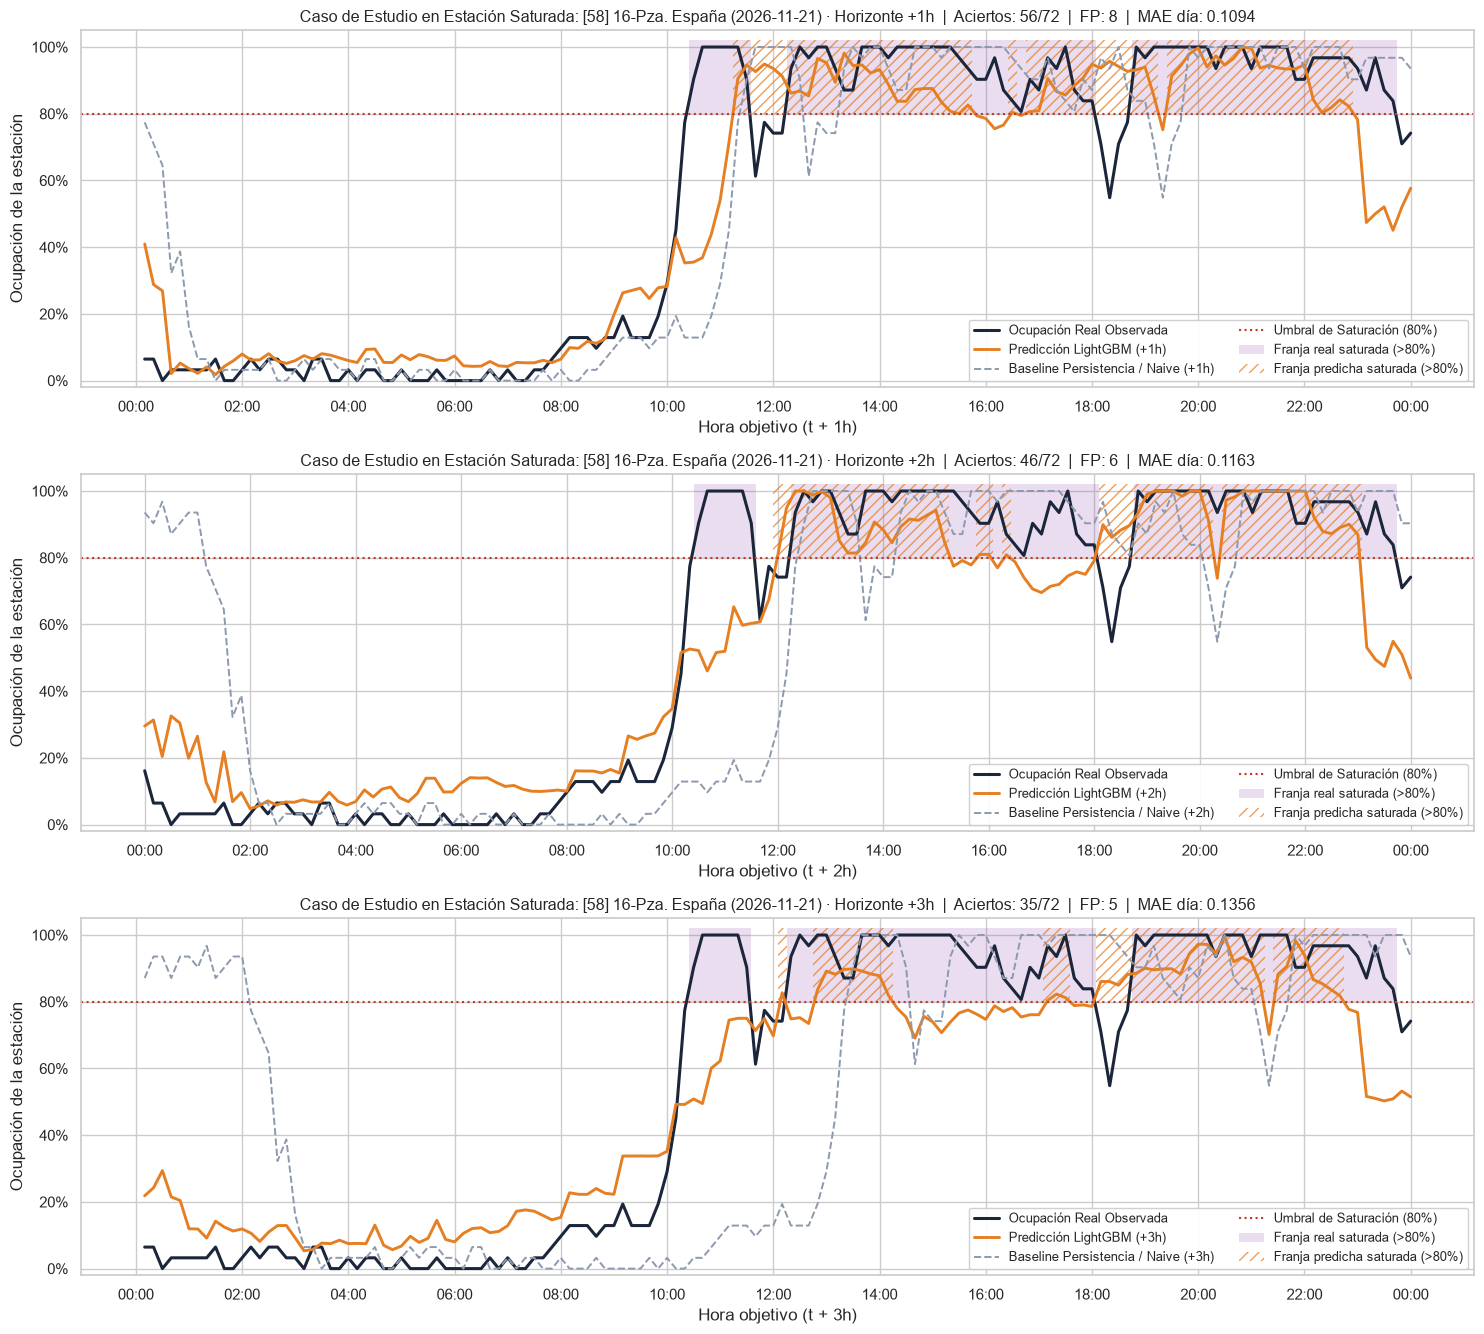

--- RESUMEN DE SATURACIÓN: [58] 16-Pza. España (2026-11-21) ---
Leyenda de abreviaturas:
  • Sat. : Saturación (ocupación > 80 %) | Occ. : Ocupación real de la estación
  • TP   : Verdadero Positivo  -> Real > 80 % y el modelo SÍ lo predijo > 80 % (acierto)
  • FN   : Falso Negativo      -> Real > 80 % pero el modelo se quedó <= 80 % (fallo crítico)
  • FP   : Falso Positivo      -> El modelo predijo > 80 % pero la real fue <= 80 % (falsa alarma)



,Real Sat. >80% [min],Aciertos (TP) [min],No Detectados (FN) [min],Real Sat. Predicho [%],Pred. sin Sat. Real (FP) [min],FP sobre Alertas [%],Occ. Real Media en FP [%]
Horizonte,,,,,,,
+1h,720,560,160,77.78,80,12.50,70.16
+2h,720,460,260,63.89,60,11.54,70.43
+3h,720,350,370,48.61,50,12.50,69.68


In [4]:
# ==============================================================================
# 2.1. CASO DE ESTUDIO TOP 1 REAL: [58] 16-Pza. España (GRÁFICA +1H, +2H, +3H)
# ==============================================================================
plot_estacion_saturada_multihorizonte(df_eval, station_id=58)
_ = resumen_saturacion_estacion(df_eval, station_id=58)

### 2.2. Top 2 Real: `[165] 162-Veterinaria`

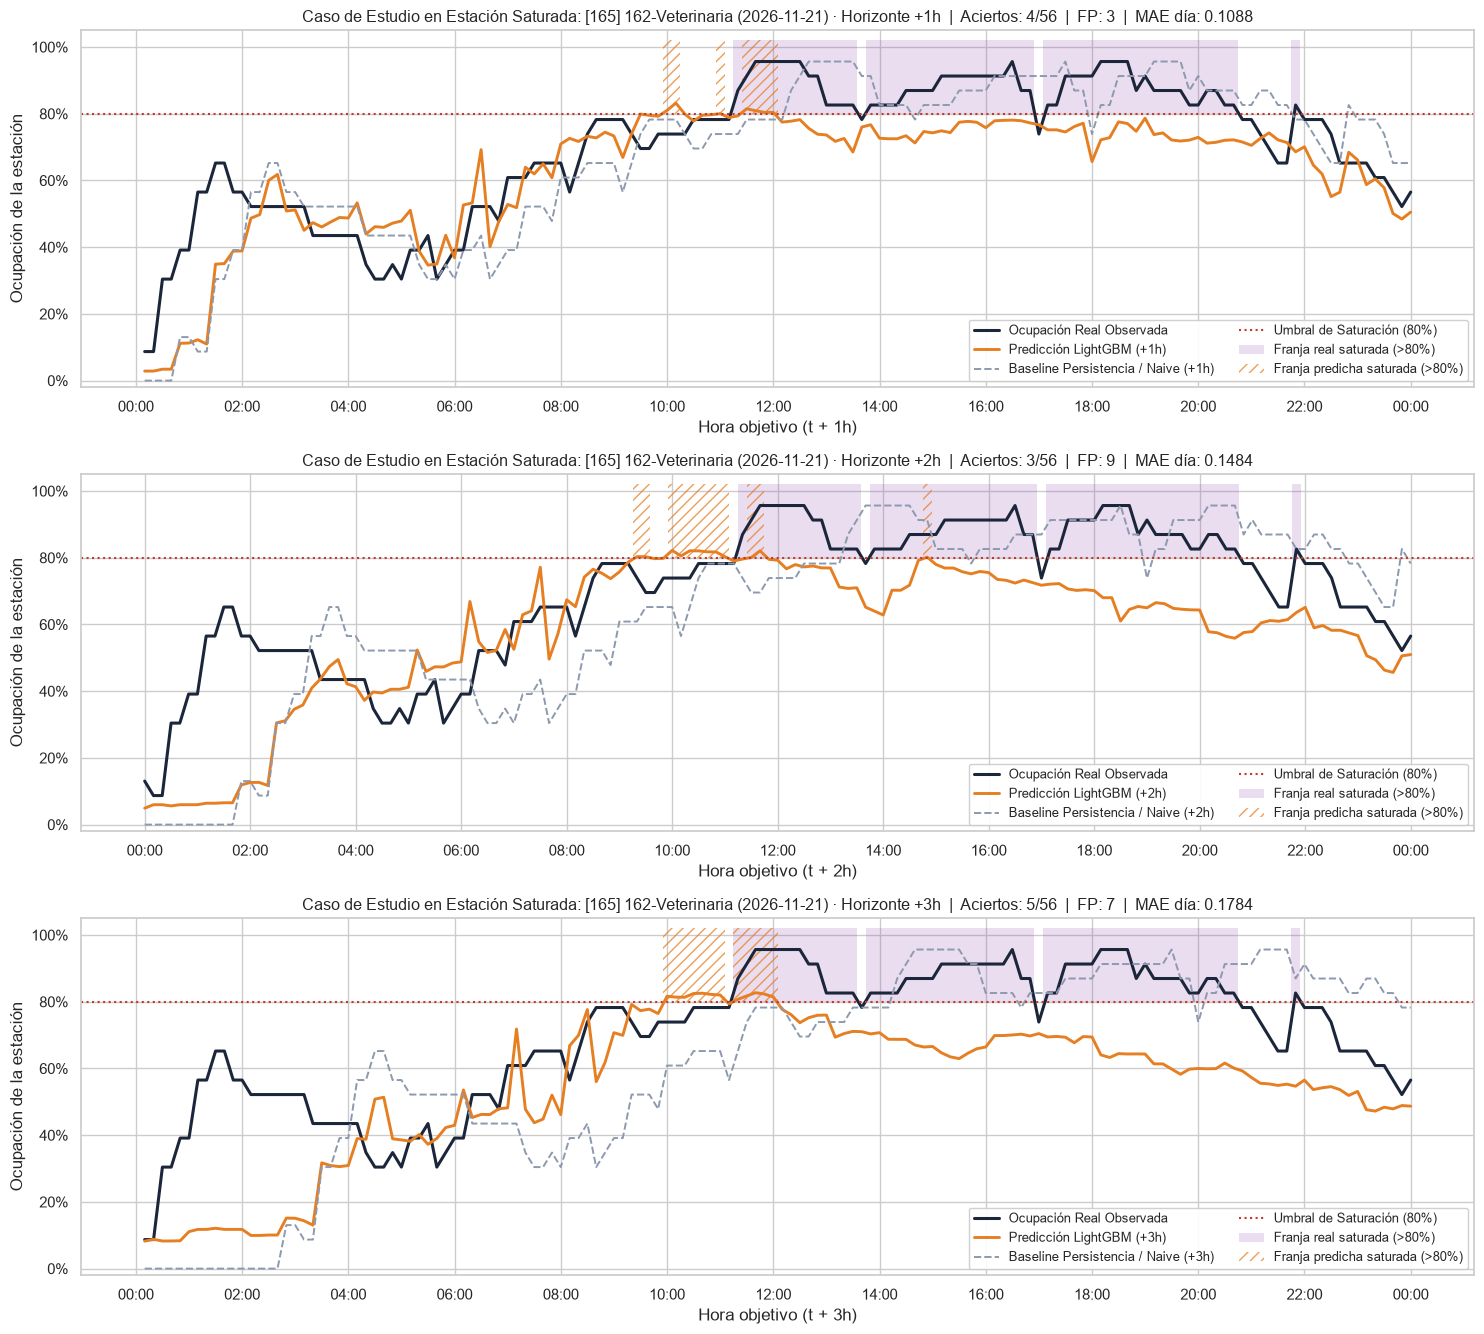

--- RESUMEN DE SATURACIÓN: [165] 162-Veterinaria (2026-11-21) ---
Leyenda de abreviaturas:
  • Sat. : Saturación (ocupación > 80 %) | Occ. : Ocupación real de la estación
  • TP   : Verdadero Positivo  -> Real > 80 % y el modelo SÍ lo predijo > 80 % (acierto)
  • FN   : Falso Negativo      -> Real > 80 % pero el modelo se quedó <= 80 % (fallo crítico)
  • FP   : Falso Positivo      -> El modelo predijo > 80 % pero la real fue <= 80 % (falsa alarma)



,Real Sat. >80% [min],Aciertos (TP) [min],No Detectados (FN) [min],Real Sat. Predicho [%],Pred. sin Sat. Real (FP) [min],FP sobre Alertas [%],Occ. Real Media en FP [%]
Horizonte,,,,,,,
+1h,560,40,520,7.14,30,42.86,75.36
+2h,560,30,530,5.36,90,75.00,75.36
+3h,560,50,510,8.93,70,58.33,76.40


In [5]:
# ==============================================================================
# 2.2. CASO DE ESTUDIO TOP 2 REAL: [165] 162-Veterinaria (GRÁFICA +1H, +2H, +3H)
# ==============================================================================
plot_estacion_saturada_multihorizonte(df_eval, station_id=165)
_ = resumen_saturacion_estacion(df_eval, station_id=165)

### 2.3. Top 3 Real: `[192] 183- Corazón de Jesús: Padua`

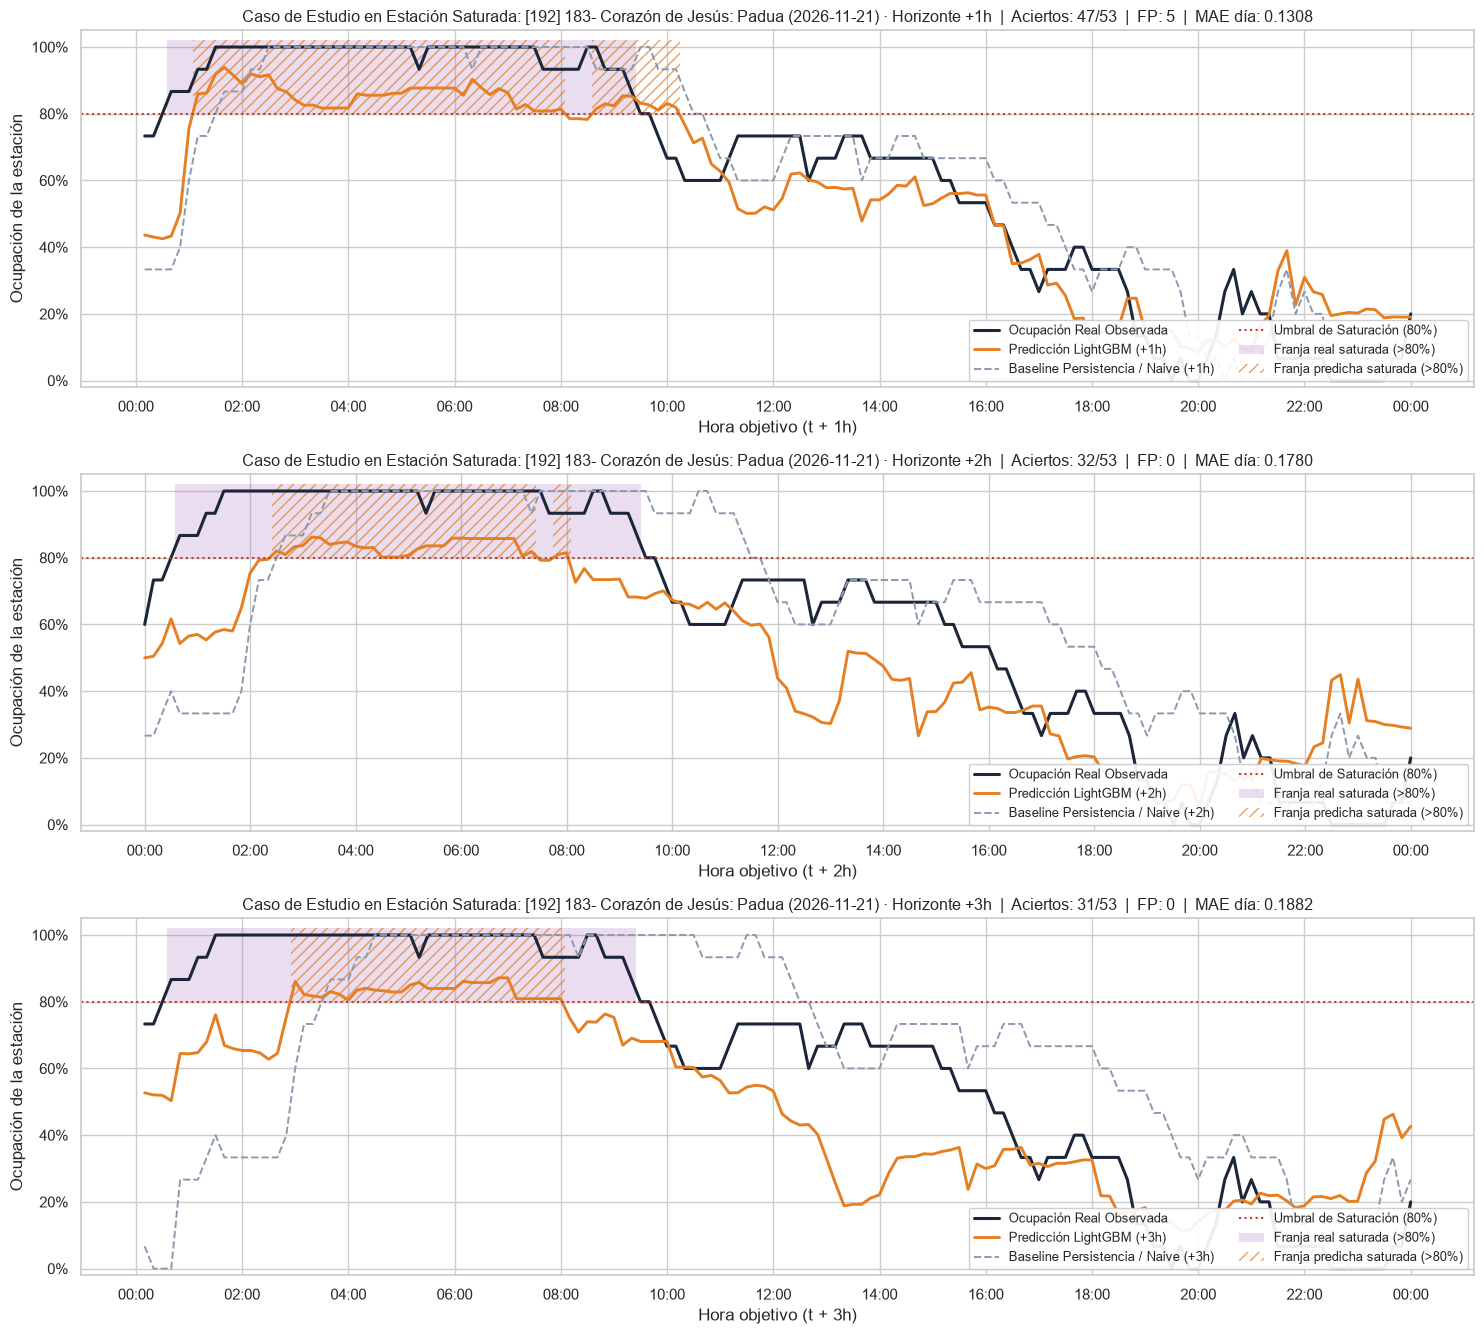

--- RESUMEN DE SATURACIÓN: [192] 183- Corazón de Jesús: Padua (2026-11-21) ---
Leyenda de abreviaturas:
  • Sat. : Saturación (ocupación > 80 %) | Occ. : Ocupación real de la estación
  • TP   : Verdadero Positivo  -> Real > 80 % y el modelo SÍ lo predijo > 80 % (acierto)
  • FN   : Falso Negativo      -> Real > 80 % pero el modelo se quedó <= 80 % (fallo crítico)
  • FP   : Falso Positivo      -> El modelo predijo > 80 % pero la real fue <= 80 % (falsa alarma)



,Real Sat. >80% [min],Aciertos (TP) [min],No Detectados (FN) [min],Real Sat. Predicho [%],Pred. sin Sat. Real (FP) [min],FP sobre Alertas [%],Occ. Real Media en FP [%]
Horizonte,,,,,,,
+1h,530,470,60,88.68,50,9.62,73.33
+2h,530,320,210,60.38,0,0.00,-
+3h,530,310,220,58.49,0,0.00,-


In [6]:
# ==============================================================================
# 2.3. CASO DE ESTUDIO TOP 3 REAL: [192] 183- Corazón de Jesús: Padua (GRÁFICA +1H, +2H, +3H)
# ==============================================================================
plot_estacion_saturada_multihorizonte(df_eval, station_id=192)
_ = resumen_saturacion_estacion(df_eval, station_id=192)

### 2.4. Top 4 Real: `[12] 23-Ribera. Azud`

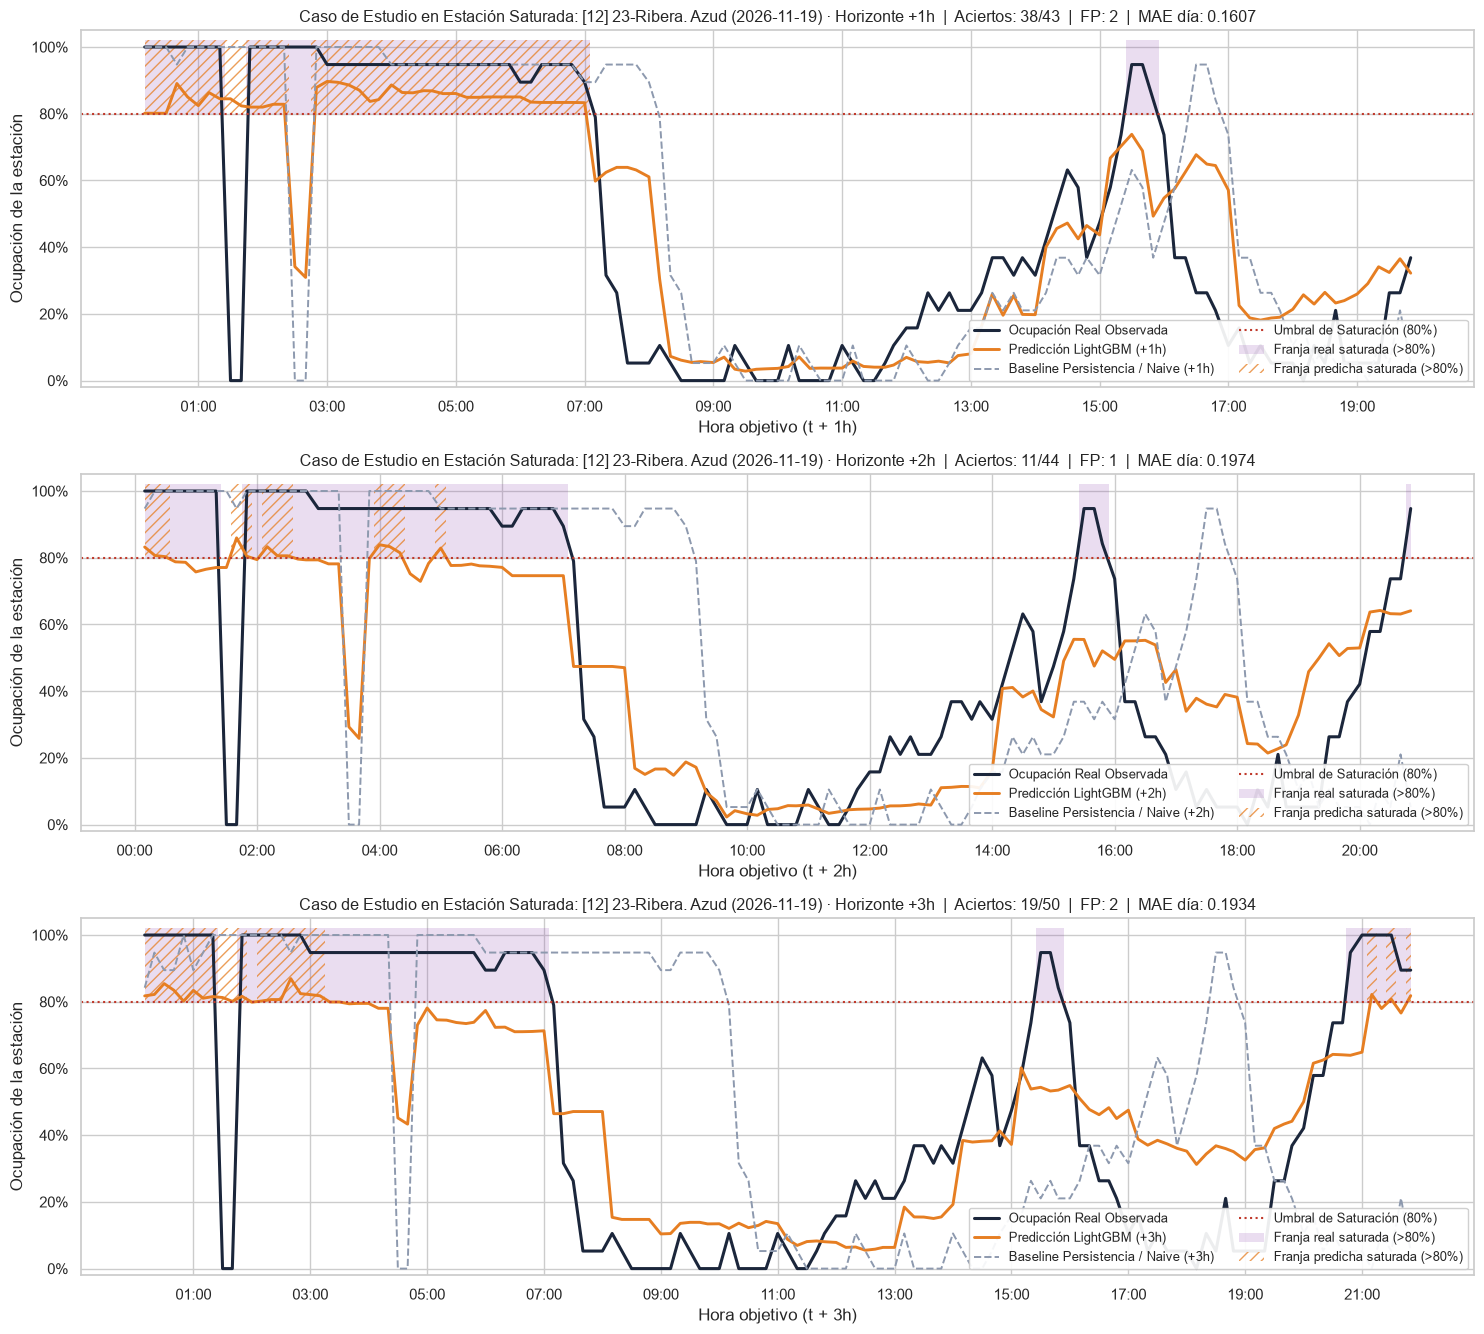

--- RESUMEN DE SATURACIÓN: [12] 23-Ribera. Azud (2026-11-19) ---
Leyenda de abreviaturas:
  • Sat. : Saturación (ocupación > 80 %) | Occ. : Ocupación real de la estación
  • TP   : Verdadero Positivo  -> Real > 80 % y el modelo SÍ lo predijo > 80 % (acierto)
  • FN   : Falso Negativo      -> Real > 80 % pero el modelo se quedó <= 80 % (fallo crítico)
  • FP   : Falso Positivo      -> El modelo predijo > 80 % pero la real fue <= 80 % (falsa alarma)



,Real Sat. >80% [min],Aciertos (TP) [min],No Detectados (FN) [min],Real Sat. Predicho [%],Pred. sin Sat. Real (FP) [min],FP sobre Alertas [%],Occ. Real Media en FP [%]
Horizonte,,,,,,,
+1h,430,380,50,88.37,20,5.00,0.00
+2h,440,110,330,25.00,10,8.33,0.00
+3h,500,190,310,38.00,20,9.52,0.00


In [7]:
# ==============================================================================
# 2.4. CASO DE ESTUDIO TOP 4 REAL: [12] 23-Ribera. Azud (GRÁFICA +1H, +2H, +3H)
# ==============================================================================
plot_estacion_saturada_multihorizonte(df_eval, station_id=12)
_ = resumen_saturacion_estacion(df_eval, station_id=12)

In [8]:
# ==============================================================================
# AUDITORÍA GLOBAL DE ANOMALÍA OFFLINE (bikes_available == 0 Y anchors_free == 0)
# ==============================================================================
mask_offline = (df_gold["bikes_available"] == 0) & (df_gold["anchors_free"] == 0)
df_offline = df_gold[mask_offline]

print("--- RESUMEN GLOBAL DE LECTURAS OFFLINE (0 BICIS Y 0 ANCLAJES LIBRES) ---")
print(f"Total registros afectados : {len(df_offline):,} de {len(df_gold):,} ({len(df_offline)/len(df_gold)*100:.4f} %)")
print(f"Estaciones afectadas      : {df_offline['station_id'].nunique()} de {df_gold['station_id'].nunique()}")
print(f"Días afectados            : {df_offline['date'].nunique()} de {df_gold['date'].nunique()}")

if not df_offline.empty:
    print("\n--- TOP 10 ESTACIONES CON MÁS LECTURAS OFFLINE ---")
    top_offline = (
        df_offline.groupby(["station_id", "name"], as_index=False)
        .agg(
            lecturas_offline=("timestamp", "count"),
            minutos_totales=("timestamp", lambda s: len(s) * FREQ_MINUTES),
            dias_distintos=("date", "nunique"),
        )
        .sort_values("lecturas_offline", ascending=False)
        .head(10)
        .reset_index(drop=True)
    )
    display(top_offline)

--- RESUMEN GLOBAL DE LECTURAS OFFLINE (0 BICIS Y 0 ANCLAJES LIBRES) ---
Total registros afectados : 361 de 782,736 (0.0461 %)
Estaciones afectadas      : 33 de 276
Días afectados            : 5 de 23

--- TOP 10 ESTACIONES CON MÁS LECTURAS OFFLINE ---


,station_id,name,lecturas_offline,minutos_totales,dias_distintos
0,215,274- Cno. Pilón: Pz. Peñetas,111,1110,3
1,153,239-Parq. Sedetania: Brea,70,700,1
2,30,65-Intercambiador Zambrano,20,200,1
3,55,102-Teatro Romano,18,180,2
4,31,4-Atarés: Pte. Almozara,16,160,2
5,276,127- Navarra: Rioja,16,160,1
6,75,49-Asturias: Santander,14,140,2
7,271,142- Ávila: Valencia,12,120,2
8,105,74-Picasso: Aleixandre,10,100,1
9,225,250- Biel: Hortensia,10,100,2


### 2.5. Top 5 Real: `[23] 14-Delicias Salidas`

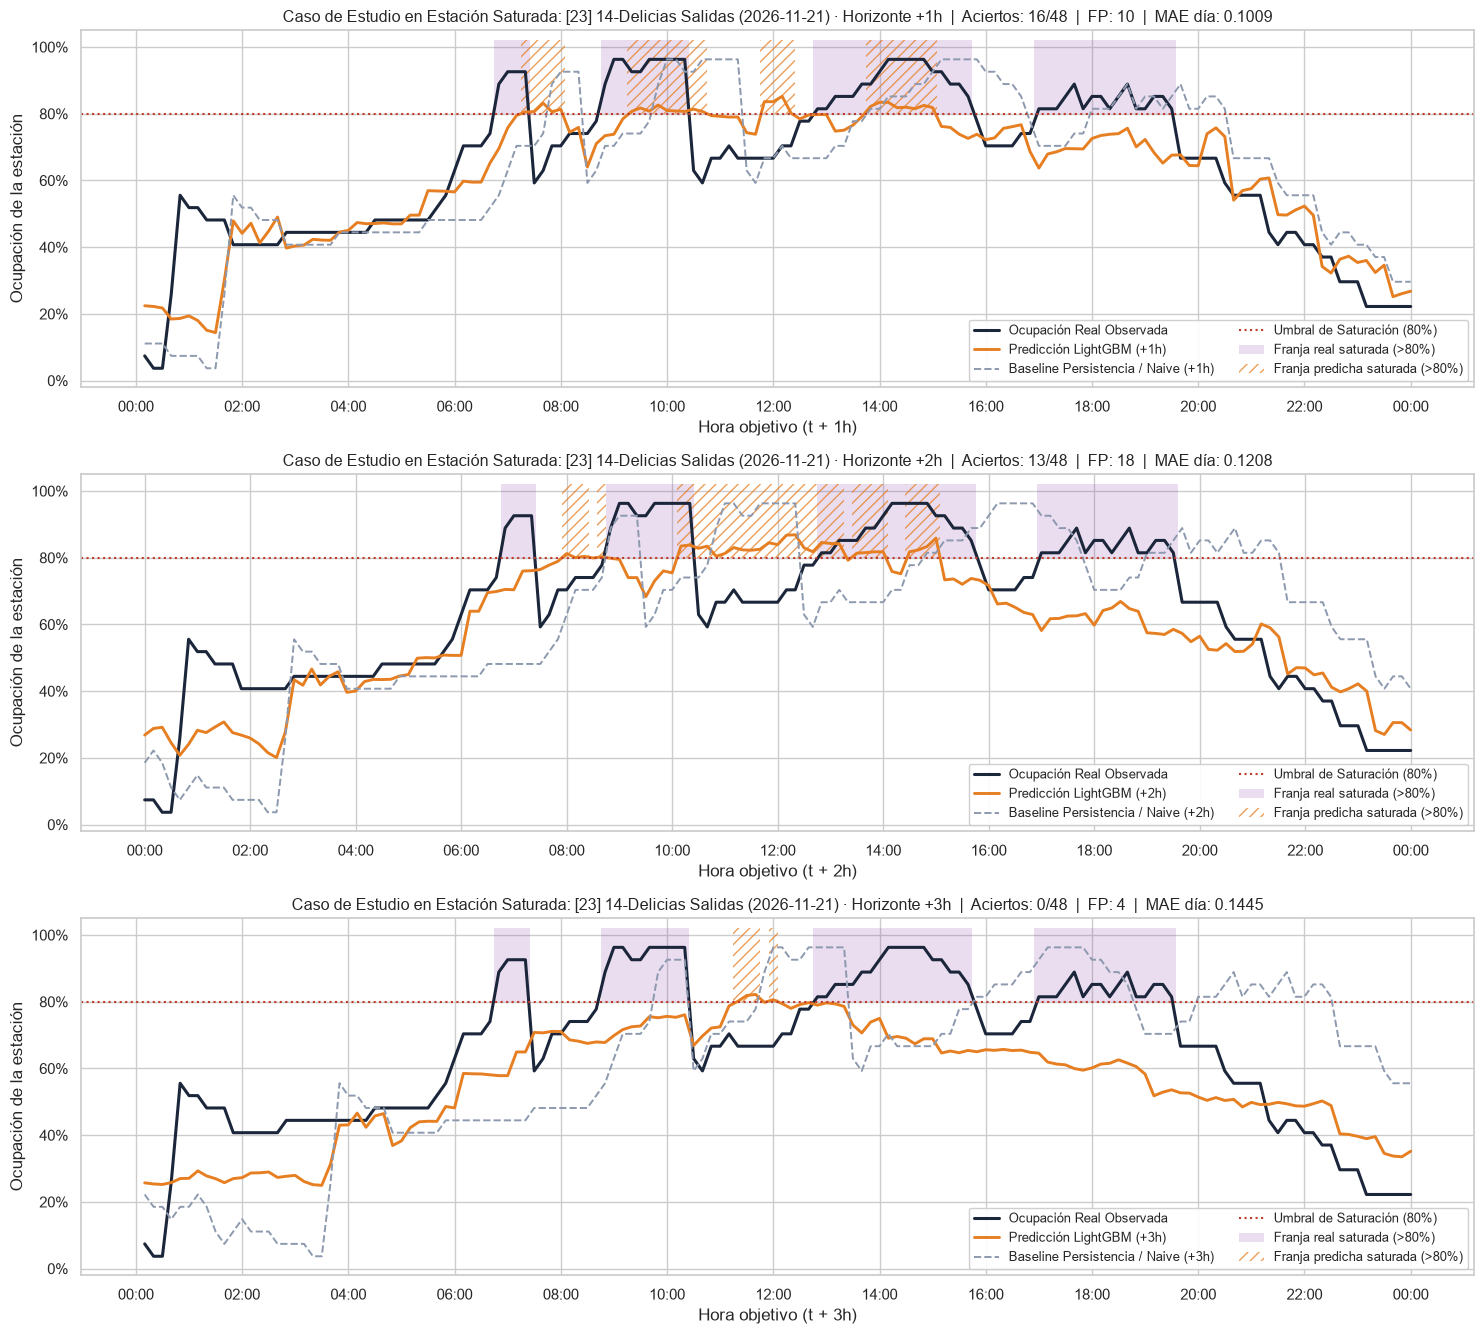

--- RESUMEN DE SATURACIÓN: [23] 14-Delicias Salidas (2026-11-21) ---
Leyenda de abreviaturas:
  • Sat. : Saturación (ocupación > 80 %) | Occ. : Ocupación real de la estación
  • TP   : Verdadero Positivo  -> Real > 80 % y el modelo SÍ lo predijo > 80 % (acierto)
  • FN   : Falso Negativo      -> Real > 80 % pero el modelo se quedó <= 80 % (fallo crítico)
  • FP   : Falso Positivo      -> El modelo predijo > 80 % pero la real fue <= 80 % (falsa alarma)



,Real Sat. >80% [min],Aciertos (TP) [min],No Detectados (FN) [min],Real Sat. Predicho [%],Pred. sin Sat. Real (FP) [min],FP sobre Alertas [%],Occ. Real Media en FP [%]
Horizonte,,,,,,,
+1h,480,160,320,33.33,100,38.46,65.93
+2h,480,130,350,27.08,180,58.06,69.55
+3h,480,0,480,0.00,40,100.00,66.67


In [9]:
# ==============================================================================
# 2.5. CASO DE ESTUDIO TOP 5 REAL: [23] 14-Delicias Salidas (GRÁFICA +1H, +2H, +3H)
# ==============================================================================
plot_estacion_saturada_multihorizonte(df_eval, station_id=23)
_ = resumen_saturacion_estacion(df_eval, station_id=23)

### 2.6. Comentarios y Observaciones sobre el Top 5 Real de Estaciones Saturadas

Tras auditar visual y numéricamente las 5 estaciones con mayor incidencia de saturación en `Test` en los tres horizontes ($+1\text{ h}$, $+2\text{ h}$ y $+3\text{ h}$), se observan cuatro patrones claros:

1. **Comportamiento muy desigual entre estaciones (dos grupos diferenciados):**
   * **Estaciones con detección razonable en corto plazo:** En `[192] 183-Corazón de Jesús: Padua` (**88,68 %** en `+1h`), `[12] 23-Ribera. Azud` (**88,37 %** en `+1h`) y `[58] 16-Pza. España` (**77,78 %** en `+1h`), el modelo logra capturar una parte importante del tiempo real de saturación a una hora vista.
   * **Estaciones prácticamente invisibles para el modelo:** En `[165] 162-Veterinaria` (560 min reales saturada), el modelo solo detecta entre el **5,36 % y el 8,93 %** del tiempo en los tres horizontes. En `[23] 14-Delicias Salidas` (480 min reales), la cobertura cae del **33,33 %** en `+1h` al **27,08 %** en `+2h` y llega al **0,00 %** en `+3h`.

2. **Fuerte pérdida de sensibilidad al ampliar el horizonte ($+1\text{ h} \rightarrow +2\text{ h} / +3\text{ h}$):**
   * Incluso en las estaciones donde `+1h` funciona bien, el porcentaje de saturación real detectado cae bruscamente en los horizontes tácticos: `Pza. España` baja del **77,78 %** al **48,61 %** (`+3h`), `Corazón de Jesús` del **88,68 %** al **58,49 %** (`+3h`) y `Ribera. Azud` se desploma del **88,37 %** (`+1h`) al **25,00 %** (`+2h`) y **38,00 %** (`+3h`).
   * Esto refleja que, cuando pierde el apoyo de la inercia inmediata, el regresor tiende a quedarse por debajo de la línea del 80 % aunque la estación permanezca saturada durante horas.

3. **Falsos positivos (FP) concentrados en ocupaciones reales altas:**
   * En las cuatro estaciones sin anomalías de sensor (`Pza. España`, `Veterinaria`, `Corazón de Jesús` y `Delicias Salidas`), cuando el modelo dispara una alerta sin saturación real, la **ocupación real media se sitúa entre el 65,93 % y el 76,40 %**. Es decir, las falsas alarmas no ocurren sobre estaciones vacías, sino en momentos en los que la estación ya está muy llena (bordes de la saturación o pequeños desfases horarios).
   * En `[192] 183-Corazón de Jesús: Padua`, directamente se registran **0 minutos de FP** en `+2h` y `+3h`.

4. **Impacto puntual de lecturas *offline* en las métricas de `[12] 23-Ribera. Azud`:**
   * Es la única estación donde la `Occ. Real Media en FP` marca **0,00 %**, pero no se debe a un error de predicción sobre una estación vacía, sino a los 20 minutos de madrugada en los que la API GBFS reportó `bikes_available = 0` y `anchors_free = 0` (estación temporalmente *offline*).

---
## 3. Estudio Visual Multi-Horizonte del Top 5 Predicho (Estaciones Exclusivas)

En esta sección auditamos las **5 primeras estaciones con mayor volumen de alertas de saturación predichas ($> 80\%$ en $+1\text{ h}$) que no habían sido analizadas en la Sección 2** *(se omiten `[58] 16-Pza. España`, `[192] 183-Corazón de Jesús: Padua` y `[12] 23-Ribera. Azud`, ya estudiadas en las subsecciones 2.1, 2.3 y 2.4)*.

Para cada estación, las funciones `plot_estacion_pred_multihorizonte` y `resumen_saturacion_pred_estacion` (definidas en el Bloque Previo) seleccionan automáticamente la jornada de `Test` en la que `LightGBM` disparó el **mayor número de alertas predichas**, permitiendo evaluar la calidad de esas alertas y caracterizar el origen de los falsos positivos en los tres horizontes ($+1\text{ h}$, $+2\text{ h}$ y $+3\text{ h}$).

### 3.1. Top 1 Predicho Exclusivo: `[11] 80-Academia Gral: Allende`

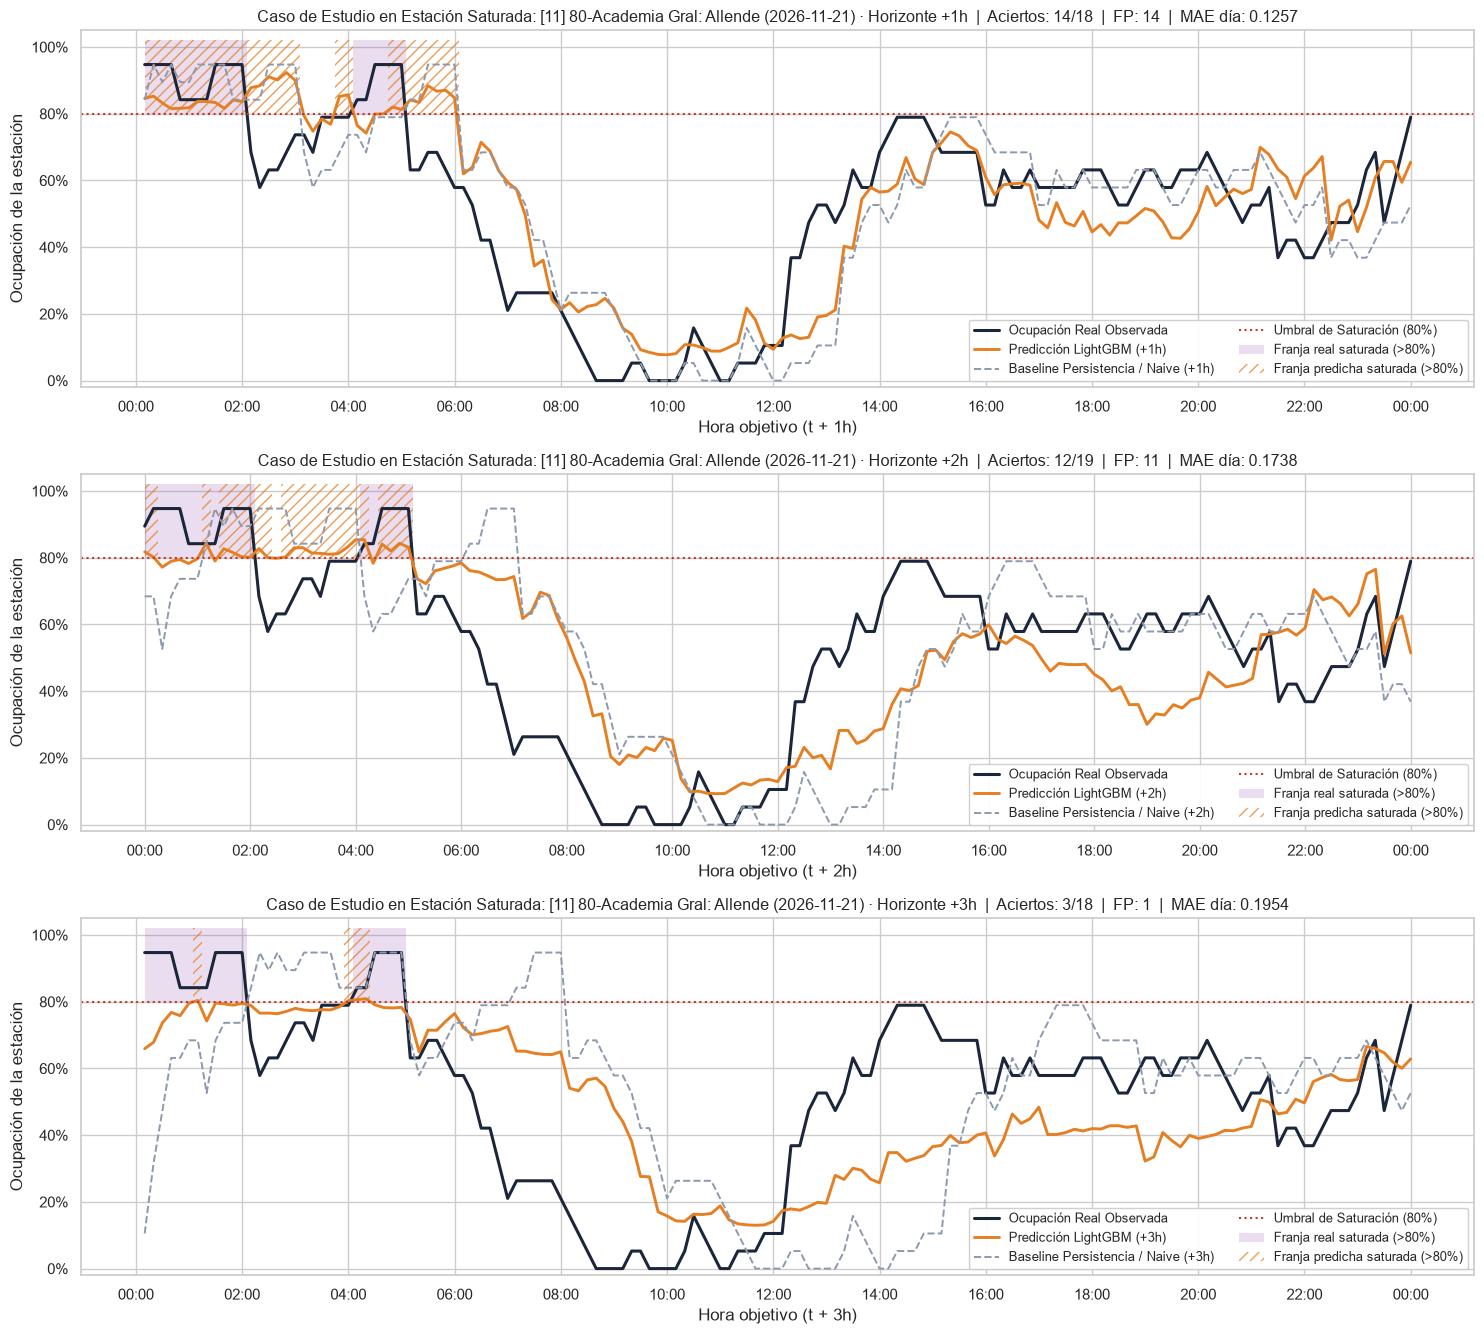

--- RESUMEN DE SATURACIÓN: [11] 80-Academia Gral: Allende (2026-11-21) ---
Leyenda de abreviaturas:
  • Sat. : Saturación (ocupación > 80 %) | Occ. : Ocupación real de la estación
  • TP   : Verdadero Positivo  -> Real > 80 % y el modelo SÍ lo predijo > 80 % (acierto)
  • FN   : Falso Negativo      -> Real > 80 % pero el modelo se quedó <= 80 % (fallo crítico)
  • FP   : Falso Positivo      -> El modelo predijo > 80 % pero la real fue <= 80 % (falsa alarma)



,Real Sat. >80% [min],Aciertos (TP) [min],No Detectados (FN) [min],Real Sat. Predicho [%],Pred. sin Sat. Real (FP) [min],FP sobre Alertas [%],Occ. Real Media en FP [%]
Horizonte,,,,,,,
+1h,180,140,40,77.78,140,50.00,66.92
+2h,190,120,70,63.16,110,47.83,71.77
+3h,180,30,150,16.67,10,25.00,78.95


In [12]:
# ==============================================================================
# 3.1. CASO DE ESTUDIO TOP 1 PREDICHO EXCLUSIVO: [11] 80-Academia Gral: Allende
# ==============================================================================
plot_estacion_pred_multihorizonte(df_eval, station_id=11)
_ = resumen_saturacion_pred_estacion(df_eval, station_id=11)

### 3.2. Top 2 Predicho Exclusivo: `[19] 78-Jardines Concordia`

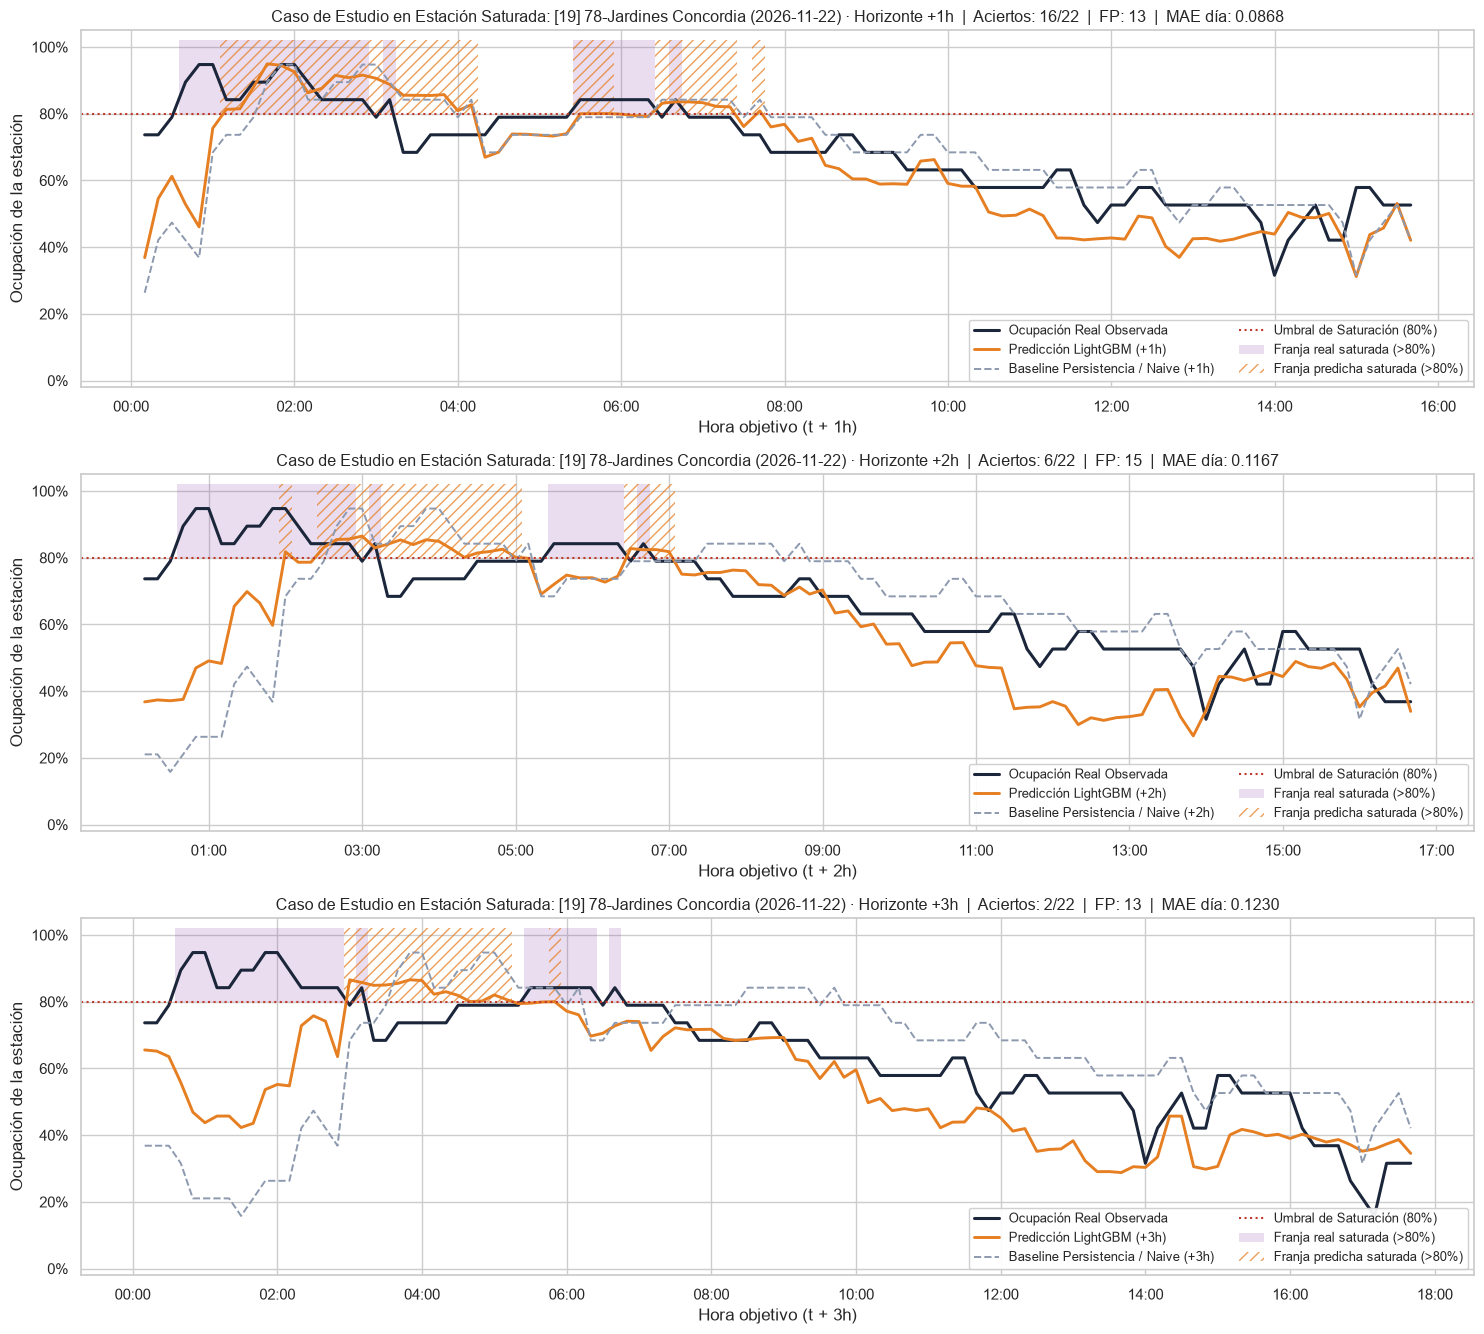

--- RESUMEN DE SATURACIÓN: [19] 78-Jardines Concordia (2026-11-22) ---
Leyenda de abreviaturas:
  • Sat. : Saturación (ocupación > 80 %) | Occ. : Ocupación real de la estación
  • TP   : Verdadero Positivo  -> Real > 80 % y el modelo SÍ lo predijo > 80 % (acierto)
  • FN   : Falso Negativo      -> Real > 80 % pero el modelo se quedó <= 80 % (fallo crítico)
  • FP   : Falso Positivo      -> El modelo predijo > 80 % pero la real fue <= 80 % (falsa alarma)



,Real Sat. >80% [min],Aciertos (TP) [min],No Detectados (FN) [min],Real Sat. Predicho [%],Pred. sin Sat. Real (FP) [min],FP sobre Alertas [%],Occ. Real Media en FP [%]
Horizonte,,,,,,,
+1h,220,160,60,72.73,130,44.83,75.30
+2h,220,60,160,27.27,150,71.43,75.79
+3h,220,20,200,9.09,130,86.67,75.30


In [13]:
# ==============================================================================
# 3.2. CASO DE ESTUDIO TOP 2 PREDICHO EXCLUSIVO: [19] 78-Jardines Concordia
# ==============================================================================
plot_estacion_pred_multihorizonte(df_eval, station_id=19)
_ = resumen_saturacion_pred_estacion(df_eval, station_id=19)

### 3.3. Top 3 Predicho Exclusivo: `[133] Allende: Rotellar`

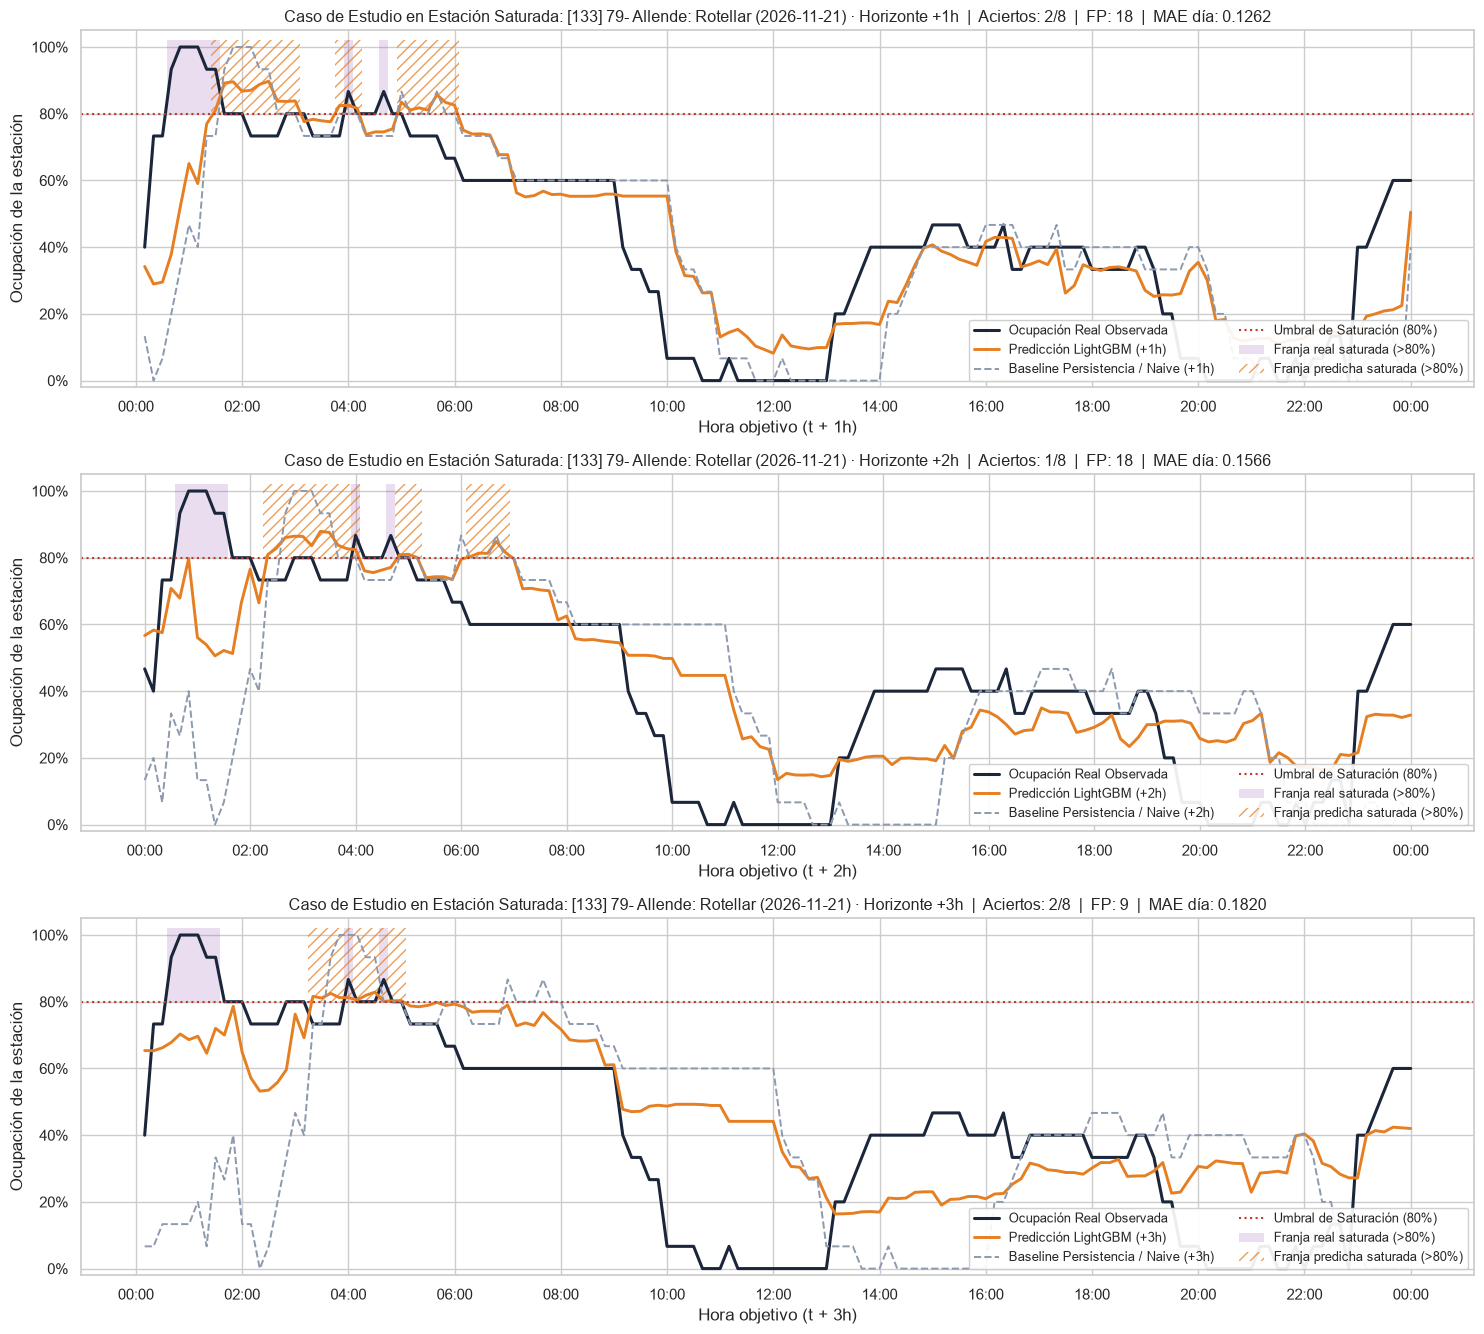

--- RESUMEN DE SATURACIÓN: [133] 79- Allende: Rotellar (2026-11-21) ---
Leyenda de abreviaturas:
  • Sat. : Saturación (ocupación > 80 %) | Occ. : Ocupación real de la estación
  • TP   : Verdadero Positivo  -> Real > 80 % y el modelo SÍ lo predijo > 80 % (acierto)
  • FN   : Falso Negativo      -> Real > 80 % pero el modelo se quedó <= 80 % (fallo crítico)
  • FP   : Falso Positivo      -> El modelo predijo > 80 % pero la real fue <= 80 % (falsa alarma)



,Real Sat. >80% [min],Aciertos (TP) [min],No Detectados (FN) [min],Real Sat. Predicho [%],Pred. sin Sat. Real (FP) [min],FP sobre Alertas [%],Occ. Real Media en FP [%]
Horizonte,,,,,,,
+1h,80,20,60,25.00,180,90.00,75.18
+2h,80,10,70,12.50,180,94.74,71.48
+3h,80,20,60,25.00,90,81.82,77.04


In [14]:
# ==============================================================================
# 3.3. CASO DE ESTUDIO TOP 3 PREDICHO EXCLUSIVO: [133] Allende: Rotellar
# ==============================================================================
plot_estacion_pred_multihorizonte(df_eval, station_id=133)
_ = resumen_saturacion_pred_estacion(df_eval, station_id=133)

### 3.4. Top 4 Predicho Exclusivo: `[222] Parq. Oeste`

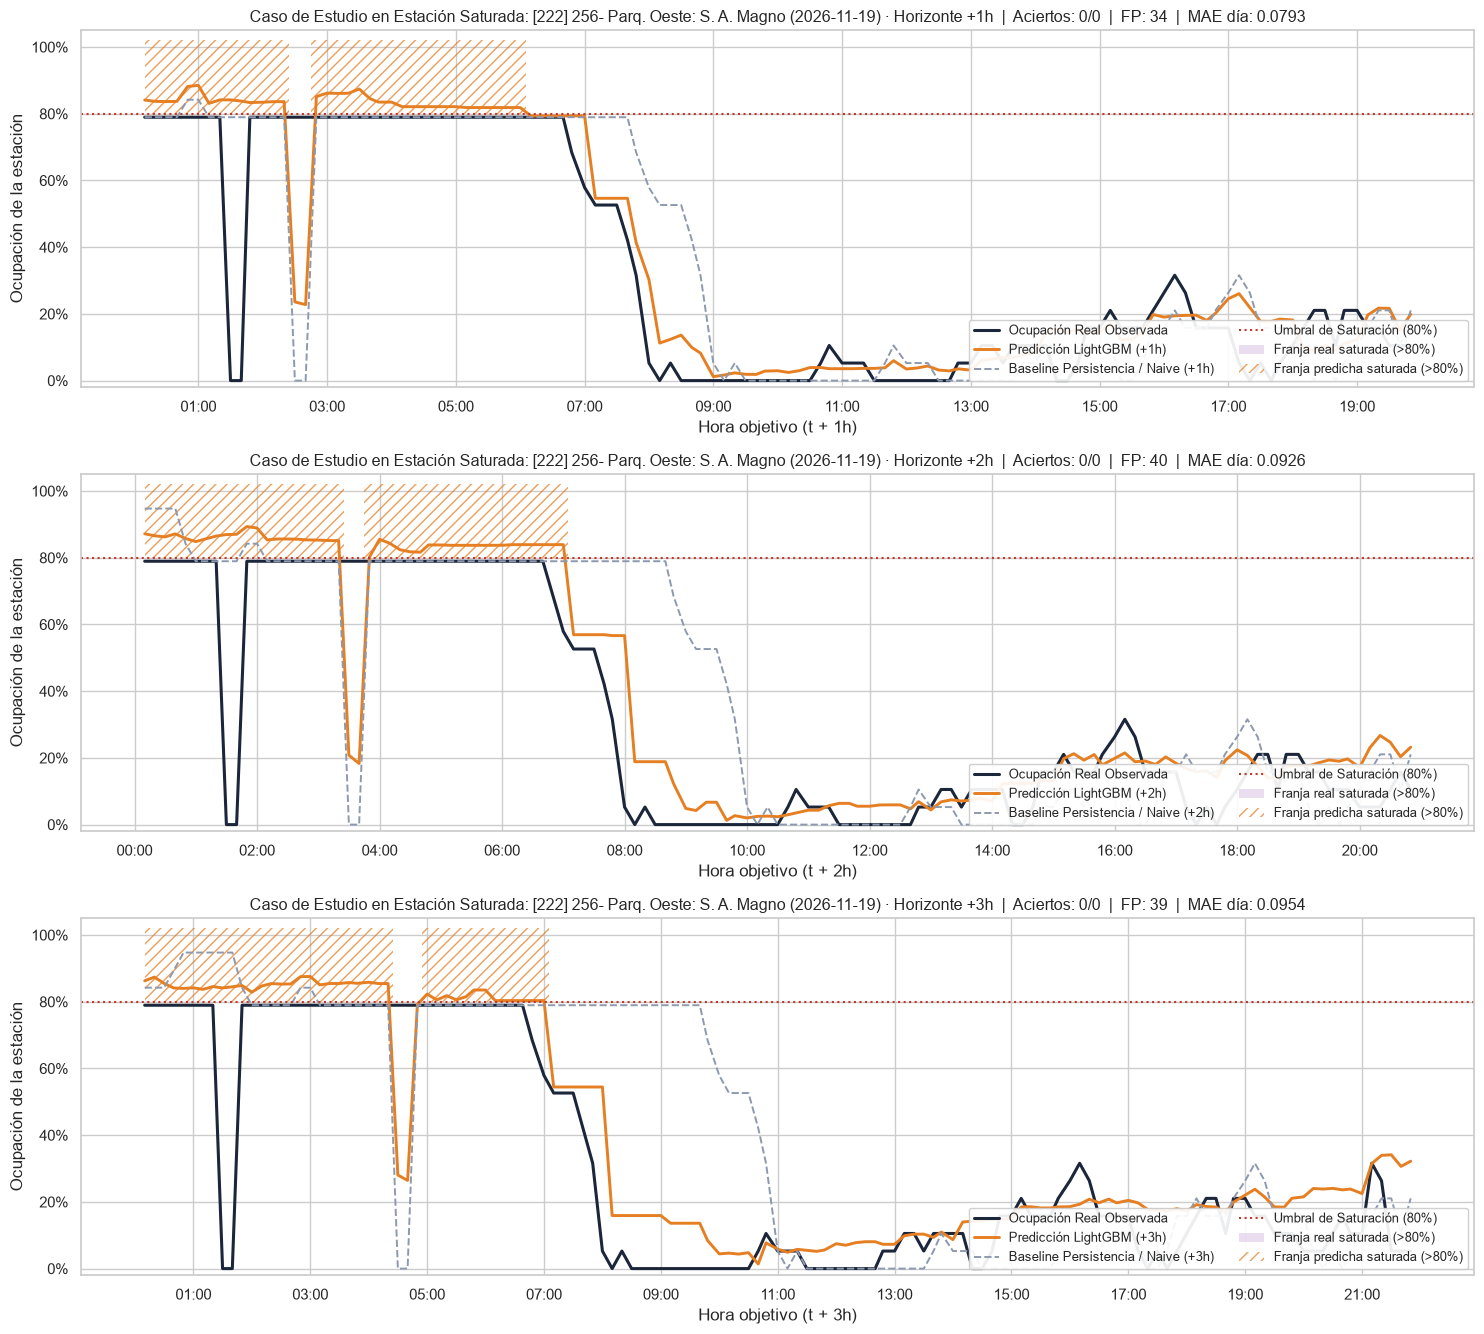

--- RESUMEN DE SATURACIÓN: [222] 256- Parq. Oeste: S. A. Magno (2026-11-19) ---
Leyenda de abreviaturas:
  • Sat. : Saturación (ocupación > 80 %) | Occ. : Ocupación real de la estación
  • TP   : Verdadero Positivo  -> Real > 80 % y el modelo SÍ lo predijo > 80 % (acierto)
  • FN   : Falso Negativo      -> Real > 80 % pero el modelo se quedó <= 80 % (fallo crítico)
  • FP   : Falso Positivo      -> El modelo predijo > 80 % pero la real fue <= 80 % (falsa alarma)



,Real Sat. >80% [min],Aciertos (TP) [min],No Detectados (FN) [min],Real Sat. Predicho [%],Pred. sin Sat. Real (FP) [min],FP sobre Alertas [%],Occ. Real Media en FP [%]
Horizonte,,,,,,,
+1h,0,0,0,0.00,340,100.00,74.31
+2h,0,0,0,0.00,400,100.00,74.21
+3h,0,0,0,0.00,390,100.00,74.09


In [17]:
# ==============================================================================
# 3.4. CASO DE ESTUDIO TOP 4 PREDICHO EXCLUSIVO: [222] Parq. Oeste
# ==============================================================================
plot_estacion_pred_multihorizonte(df_eval, station_id=222)
_ = resumen_saturacion_pred_estacion(df_eval, station_id=222)

### 3.5. Top 5 Predicho Exclusivo: `[98] Auditorio`

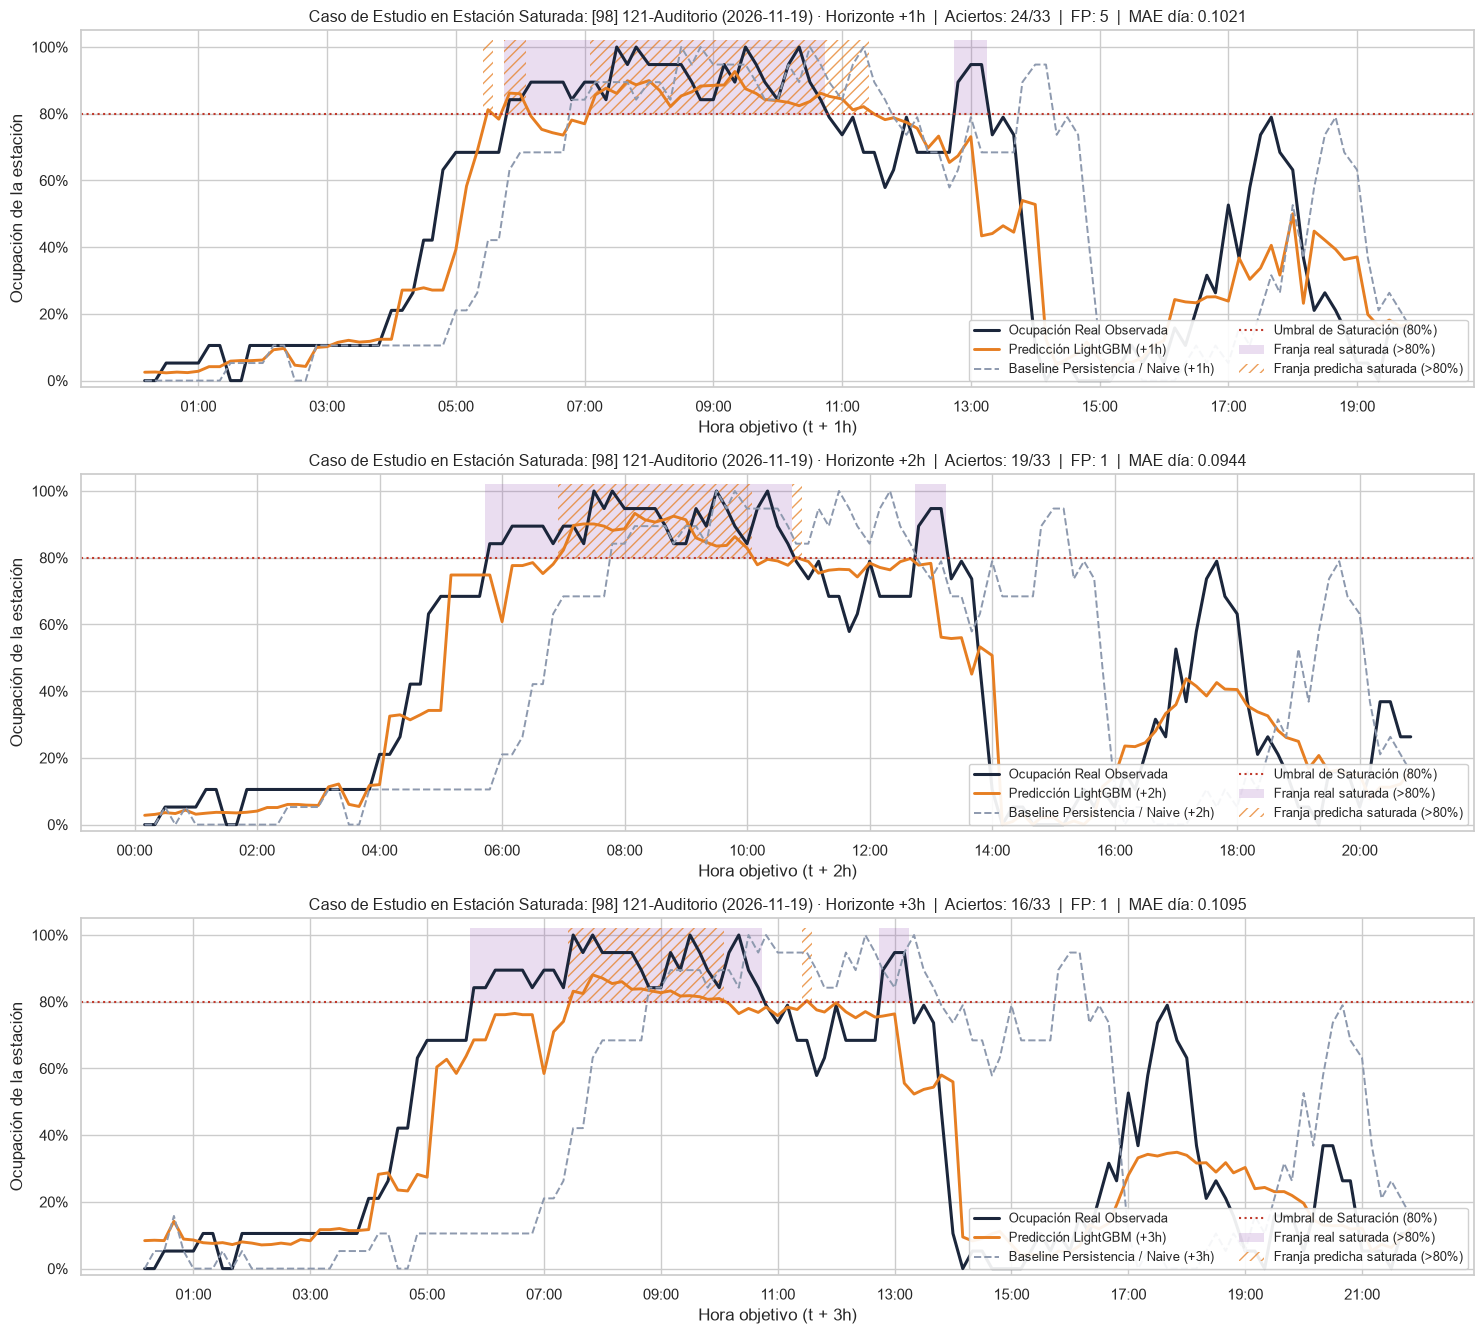

--- RESUMEN DE SATURACIÓN: [98] 121-Auditorio (2026-11-19) ---
Leyenda de abreviaturas:
  • Sat. : Saturación (ocupación > 80 %) | Occ. : Ocupación real de la estación
  • TP   : Verdadero Positivo  -> Real > 80 % y el modelo SÍ lo predijo > 80 % (acierto)
  • FN   : Falso Negativo      -> Real > 80 % pero el modelo se quedó <= 80 % (fallo crítico)
  • FP   : Falso Positivo      -> El modelo predijo > 80 % pero la real fue <= 80 % (falsa alarma)



,Real Sat. >80% [min],Aciertos (TP) [min],No Detectados (FN) [min],Real Sat. Predicho [%],Pred. sin Sat. Real (FP) [min],FP sobre Alertas [%],Occ. Real Media en FP [%]
Horizonte,,,,,,,
+1h,330,240,90,72.73,50,17.24,73.68
+2h,330,190,140,57.58,10,5.00,78.95
+3h,330,160,170,48.48,10,5.88,68.42


In [19]:
# ==============================================================================
# 3.5. CASO DE ESTUDIO TOP 5 PREDICHO EXCLUSIVO: [98] Auditorio
# ==============================================================================
plot_estacion_pred_multihorizonte(df_eval, station_id=98)
_ = resumen_saturacion_pred_estacion(df_eval, station_id=98)

### 3.6. Comentarios y Observaciones sobre el Top 5 Predicho (Estaciones Exclusivas)

Tras auditar las 5 estaciones exclusivas con mayor volumen de alertas predichas en `Test` en los tres horizontes ($+1\text{ h}$, $+2\text{ h}$ y $+3\text{ h}$), se desprenden tres observaciones principales:

1. **Dos perfiles diferenciados en la fiabilidad de las alertas:**
   * **Estaciones con saturación real relevante y buena detección en corto plazo:** `[98] 121-Auditorio` presenta el comportamiento más equilibrado, capturando el **72,73 %** de los 330 min reales en `+1h` con una tasa de falsas alarmas muy contenida (**17,24 %** en `+1h`, **5,00 %** en `+2h` y **5,88 %** en `+3h`). En un término medio se sitúan `[11] 80-Academia Gral: Allende` (**77,78 %** de cobertura en `+1h` y **63,16 %** en `+2h`, con un ~48–50 % de FP sobre alertas) y `[19] 78-Jardines Concordia` (**72,73 %** en `+1h`, pero con 130 min de FP).
   * **Estaciones dominadas por falsas alarmas:** `[222] 256-Parq. Oeste: S. A. Magno` acumula **0 minutos de saturación real** en toda la jornada, pero el modelo dispara entre **340 y 400 minutos de alertas** (**100,00 %** de FP en los tres horizontes). De forma similar, `[133] 79-Allende: Rotellar` apenas registra 80 min reales, frente a **90–180 min de FP** (**81,82 %–94,74 %** de sus alertas).

2. **Los falsos positivos se concentran sistemáticamente en estados de "casi-saturación":**
   * En las cinco estaciones y en todos los horizontes, la **ocupación real media durante los FP se sitúa entre el 66,92 % y el 78,95 %**.
   * Incluso en el caso más extremo (`[222] Parq. Oeste`, 100 % FP), la ocupación real media durante las alertas es del **74,09 %–74,31 %**. Esto confirma que el modelo no genera alertas en estaciones vacías o a media carga, sino que cruza ligeramente la frontera del 80 % en estaciones que permanecen de forma sostenida en la franja del 70 %–79 %.

3. **Caída de aciertos y persistencia de falsas alarmas en $+2\text{ h}$ y $+3\text{ h}$:**
   * Al igual que en el Top 5 Real, el porcentaje de saturación real detectado cae con el horizonte: `Jardines Concordia` baja del **72,73 %** (`+1h`) al **27,27 %** (`+2h`) y **9,09 %** (`+3h`); `Academia Gral: Allende` cae del **77,78 %** al **16,67 %** (`+3h`); y `Auditorio` del **72,73 %** al **48,48 %** (`+3h`).
   * En cambio, en estaciones como `Parq. Oeste` (340 $\rightarrow$ 400 $\rightarrow$ 390 min) y `Jardines Concordia` (130 $\rightarrow$ 150 $\rightarrow$ 130 min), el volumen de falsos positivos se mantiene estable en horizontes largos, elevando el peso de los FP sobre el total de alertas hasta el **86,67 %–100,00 %**.

---
## 4. Diagnóstico de Subestimación en Saturación y Viabilidad del *Threshold Tuning*

Tras comprobar en las Secciones 2 y 3 que el regresor `LightGBM (Optuna)` suaviza los picos de llenado y tiende a quedarse por debajo del $80\%$ en horizontes tácticos ($+2\text{ h}$ y $+3\text{ h}$), en esta sección respondemos a una pregunta clave de arquitectura:

> **¿El modelo ya separa bien las estaciones saturadas pero con un sesgo a la baja (solucionable ajustando el umbral de decisión / *threshold tuning*), o existe un solapamiento estructural que exige un clasificador auxiliar específico?**

Para responderlo con evidencia en `Test`, analizamos:
1. La **distribución exacta de las predicciones** cuando la estación está realmente saturada ($> 80\%$) frente a cuando no lo está.
2. Un **barrido de umbrales de alerta** ($\tau \in [0.55, 0.80]$) midiendo el compromiso entre *Recall*, *Precision*, *F1 Saturada* y la ocupación real media de las falsas alarmas.

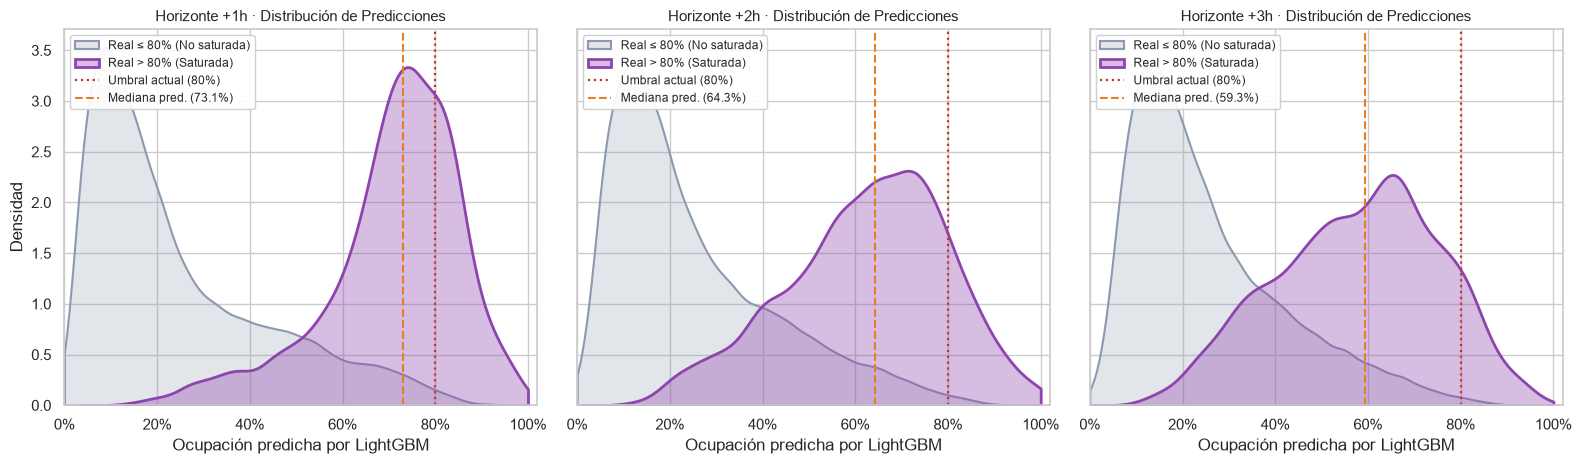

--- ESTADÍSTICOS DE PREDICCIÓN CUANDO LA OCUPACIÓN REAL ES > 80 % (TEST) ---
Leyenda de columnas y unidades:
  • Real Sat. >80% [min]: Tiempo total acumulado en Test con ocupación real superior al 80 % [min]
  • Real / Pred. Media  : Ocupación media observada vs. predicha por LightGBM [%]
  • Sesgo Medio [pp]    : Diferencia (Pred. Media - Real Media) en puntos porcentuales (negativo = subestimación)
  • Pred. P25/Med/P75   : Percentiles 25, 50 (mediana) y 75 de la ocupación predicha en esos casos [%]
  • % con Pred >70/65%  : Proporción de tiempo saturado real en el que LightGBM predijo > 70 % o > 65 % [%]



,Real Sat. >80% [min],Real Media [%],Pred. Media [%],Sesgo Medio [pp],Pred. P25 [%],Pred. Mediana [%],Pred. P75 [%],% con Pred >70%,% con Pred >65%
Horizonte,,,,,,,,,
+1h,"52,300",91.04,70.80,-20.24,64.32,73.15,80.89,60.65,73.79
+2h,"52,340",91.06,62.45,-28.61,51.25,64.28,75.00,37.50,48.28
+3h,"51,990",91.05,57.73,-33.31,45.24,59.32,70.57,26.04,37.66


In [23]:
# ==============================================================================
# 4.1. DISTRIBUCIÓN DE PREDICCIONES CUANDO LA OCUPACIÓN REAL SUPERA EL 80 %
# ==============================================================================
filas_dist = []

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)

for idx, h in enumerate(HORIZONS_HOURS):
    real_col = f"target_occ_{h}h"
    pred_col = f"pred_lgbm_{h}h"
    sat_mask = df_eval[real_col] > OCCUPANCY_HIGH_THRESHOLD

    preds_sat = df_eval.loc[sat_mask, pred_col]
    preds_nosat = df_eval.loc[~sat_mask, pred_col]
    real_sat_vals = df_eval.loc[sat_mask, real_col]

    filas_dist.append({
        "Horizonte": f"+{h}h",
        "Real Sat. >80% [min]": int(sat_mask.sum()) * FREQ_MINUTES,
        "Real Media [%]": round(real_sat_vals.mean() * 100, 2),
        "Pred. Media [%]": round(preds_sat.mean() * 100, 2),
        "Sesgo Medio [pp]": round((preds_sat.mean() - real_sat_vals.mean()) * 100, 2),
        "Pred. P25 [%]": round(preds_sat.quantile(0.25) * 100, 2),
        "Pred. Mediana [%]": round(preds_sat.median() * 100, 2),
        "Pred. P75 [%]": round(preds_sat.quantile(0.75) * 100, 2),
        "% con Pred >70%": round((preds_sat > 0.70).mean() * 100, 2),
        "% con Pred >65%": round((preds_sat > 0.65).mean() * 100, 2),
    })

    # Gráfico de densidad: predicciones en saturación real vs. no saturación
    ax = axes[idx]
    sns.kdeplot(
        preds_nosat,
        ax=ax,
        color="#8d99ae",
        fill=True,
        alpha=0.25,
        linewidth=1.5,
        label="Real ≤ 80% (No saturada)",
        clip=(0, 1),
    )
    sns.kdeplot(
        preds_sat,
        ax=ax,
        color="#8e44ad",
        fill=True,
        alpha=0.35,
        linewidth=2.0,
        label="Real > 80% (Saturada)",
        clip=(0, 1),
    )
    ax.axvline(
        OCCUPANCY_HIGH_THRESHOLD,
        color="#c0392b",
        linestyle=":",
        linewidth=1.6,
        label="Umbral actual (80%)",
    )
    ax.axvline(
        preds_sat.median(),
        color="#e67e22",
        linestyle="--",
        linewidth=1.5,
        label=f"Mediana pred. ({preds_sat.median()*100:.1f}%)",
    )
    ax.set_title(f"Horizonte +{h}h · Distribución de Predicciones", fontsize=11)
    ax.set_xlabel("Ocupación predicha por LightGBM")
    ax.set_xlim(0, 1.02)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    if idx == 0:
        ax.set_ylabel("Densidad")
    ax.legend(loc="upper left", fontsize=8.5, framealpha=0.92)

plt.tight_layout()
plt.show()

df_dist_sat = pd.DataFrame(filas_dist).set_index("Horizonte")
print("--- ESTADÍSTICOS DE PREDICCIÓN CUANDO LA OCUPACIÓN REAL ES > 80 % (TEST) ---")
print("Leyenda de columnas y unidades:")
print("  • Real Sat. >80% [min]: Tiempo total acumulado en Test con ocupación real superior al 80 % [min]")
print("  • Real / Pred. Media  : Ocupación media observada vs. predicha por LightGBM [%]")
print("  • Sesgo Medio [pp]    : Diferencia (Pred. Media - Real Media) en puntos porcentuales (negativo = subestimación)")
print("  • Pred. P25/Med/P75   : Percentiles 25, 50 (mediana) y 75 de la ocupación predicha en esos casos [%]")
print("  • % con Pred >70/65%  : Proporción de tiempo saturado real en el que LightGBM predijo > 70 % o > 65 % [%]\n")

display(
    df_dist_sat.style.format(
        {
            "Real Sat. >80% [min]": "{:,.0f}",
            "Real Media [%]": "{:.2f}",
            "Pred. Media [%]": "{:.2f}",
            "Sesgo Medio [pp]": "{:+.2f}",
            "Pred. P25 [%]": "{:.2f}",
            "Pred. Mediana [%]": "{:.2f}",
            "Pred. P75 [%]": "{:.2f}",
            "% con Pred >70%": "{:.2f}",
            "% con Pred >65%": "{:.2f}",
        }
    )
)

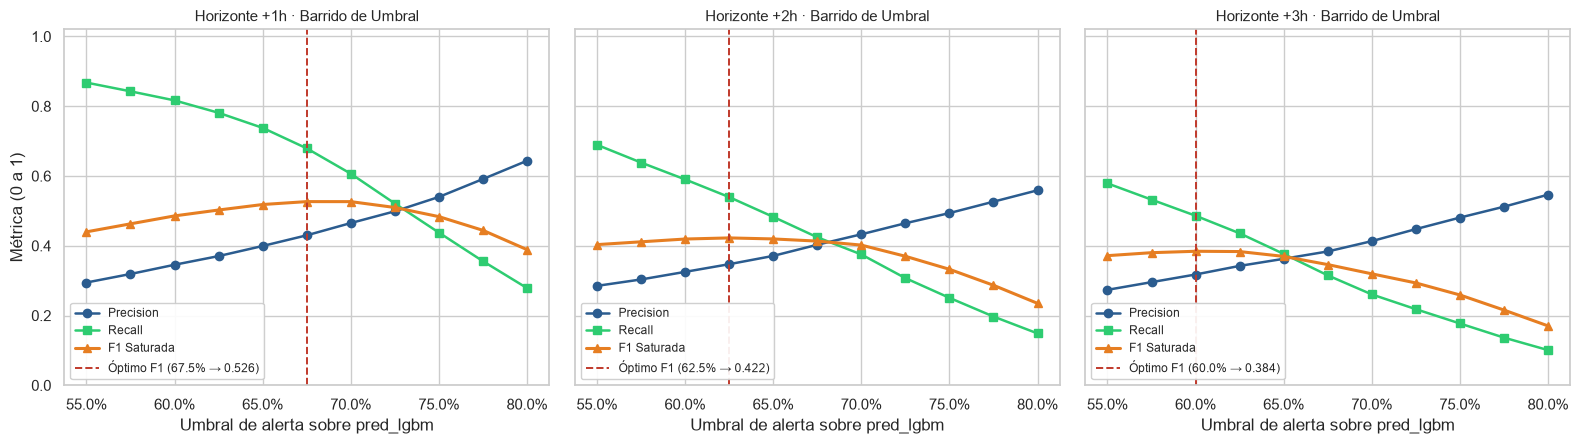

--- COMPARATIVA: UMBRAL ESTÁNDAR (80 %) VS. THRESHOLD TUNING ÓPTIMO (F1) ---


In [21]:
# ==============================================================================
# 4.2. BARRIDO DE UMBRALES DE DECISIÓN (THRESHOLD TUNING: 0.55 A 0.80)
# ==============================================================================
umbrales = np.round(np.arange(0.55, 0.801, 0.025), 3)
registros_tuning = []

for h in HORIZONS_HOURS:
    real_sat = df_eval[f"real_sat_{h}h"].to_numpy()
    real_occ = df_eval[f"target_occ_{h}h"].to_numpy()
    pred_occ = df_eval[f"pred_lgbm_{h}h"].to_numpy()

    for th in umbrales:
        pred_sat_th = (pred_occ > th).astype(int)
        fp_mask = (real_sat == 0) & (pred_sat_th == 1)

        registros_tuning.append({
            "Horizonte": f"+{h}h",
            "Umbral": th,
            "Precision": precision_score(real_sat, pred_sat_th, zero_division=0),
            "Recall": recall_score(real_sat, pred_sat_th, zero_division=0),
            "F1 Saturada": f1_score(real_sat, pred_sat_th, zero_division=0),
            "Alertas Totales": int(pred_sat_th.sum()),
            "FP Totales": int(fp_mask.sum()),
            "Occ. Real Media en FP [%]": round(real_occ[fp_mask].mean() * 100, 2)
            if fp_mask.sum() > 0
            else np.nan,
        })

df_tuning = pd.DataFrame(registros_tuning)

# Gráfica de curvas Precision / Recall / F1 frente al umbral
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)

for idx, h in enumerate(HORIZONS_HOURS):
    ax = axes[idx]
    sub = df_tuning[df_tuning["Horizonte"] == f"+{h}h"]
    best_row = sub.loc[sub["F1 Saturada"].idxmax()]

    ax.plot(sub["Umbral"], sub["Precision"], marker="o", linewidth=1.8, color="#2b5c8f", label="Precision")
    ax.plot(sub["Umbral"], sub["Recall"], marker="s", linewidth=1.8, color="#2ecc71", label="Recall")
    ax.plot(sub["Umbral"], sub["F1 Saturada"], marker="^", linewidth=2.2, color="#e67e22", label="F1 Saturada")

    ax.axvline(
        best_row["Umbral"],
        color="#c0392b",
        linestyle="--",
        linewidth=1.4,
        label=f"Óptimo F1 ({best_row['Umbral']*100:.1f}% → {best_row['F1 Saturada']:.3f})",
    )
    ax.set_title(f"Horizonte +{h}h · Barrido de Umbral", fontsize=11)
    ax.set_xlabel("Umbral de alerta sobre pred_lgbm")
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.set_ylim(0, 1.02)
    if idx == 0:
        ax.set_ylabel("Métrica (0 a 1)")
    ax.legend(loc="lower left", fontsize=8.5, framealpha=0.92)

plt.tight_layout()
plt.show()

# Comparativa directa: Umbral actual (80%) vs. Umbral óptimo en F1 por horizonte
filas_comp = []
for h in HORIZONS_HOURS:
    sub = df_tuning[df_tuning["Horizonte"] == f"+{h}h"]
    base_row = sub[sub["Umbral"] == 0.80].iloc[0]
    best_row = sub.loc[sub["F1 Saturada"].idxmax()]

    for etiqueta, row in [("Base (80.0%)", base_row), (f"Óptimo F1 ({row['Umbral']*100:.1f}%)" if False else f"Óptimo F1 ({best_row['Umbral']*100:.1f}%)", best_row)]:
        filas_comp.append({
            "Horizonte": f"+{h}h",
            "Configuración": etiqueta,
            "Precision": round(row["Precision"], 4),
            "Recall": round(row["Recall"], 4),
            "F1 Saturada": round(row["F1 Saturada"], 4),
            "Alertas Totales": int(row["Alertas Totales"]),
            "FP Totales": int(row["FP Totales"]),
            "Occ. Real Media en FP [%]": row["Occ. Real Media en FP [%]"],
        })

df_comp_th = pd.DataFrame(filas_comp).set_index(["Horizonte", "Configuración"])
print("--- COMPARATIVA: UMBRAL ESTÁNDAR (80 %) VS. THRESHOLD TUNING ÓPTIMO (F1) ---")
display(
    df_comp_th.style.format(
        {
            "Precision": "{:.4f}",
            "Recall": "{:.4f}",
            "F1 Saturada": "{:.4f}",
            "Alertas Totales": "{:,.0f}",
            "FP Totales": "{:,.0f}",
            "Occ. Real Media en FP [%]": "{:.2f}",
        },
        na_rep="-",
    )
)

### 4.3. Conclusiones del Diagnóstico y Decisión Arquitectónica

El análisis de la distribución de predicciones (4.1) y el barrido de umbrales (4.2) sobre el conjunto de `Test` (~52.000 minutos acumulados de saturación real por horizonte) permite cerrar el diagnóstico con cuatro conclusiones clave:

1. **Subestimación sistemática creciente con el horizonte:**
   * Cuando una estación supera el umbral de saturación (ocupación real media constante de **91,0 %**), el regresor `LightGBM (Optuna)` predice de media **70,80 %** en `+1h`, **62,45 %** en `+2h` y **57,73 %** en `+3h`, lo que supone un sesgo negativo de **-20,24 pp**, **-28,61 pp** y **-33,31 pp** respectivamente.
   * En los horizontes tácticos (`+2h` y `+3h`), ni siquiera el **percentil 75** de las predicciones alcanza la barrera del 80 % (**75,00 %** y **70,57 %**), confirmando que más de tres cuartas partes de las saturaciones reales quedan invisibles bajo el umbral estándar.

2. **Buena separabilidad en corto plazo (`+1h`) frente a solapamiento estructural en `+2h` y `+3h`:**
   * En **`+1h`**, la distribución de predicciones en saturación real mantiene una forma compacta y bien diferenciada de los estados no saturados, pero desplazada a la izquierda (mediana en **73,15 %** y el **73,79 %** de los casos por encima del 65 %). El problema principal es de **calibración/sesgo**.
   * En **`+2h` y `+3h`**, la curva se aplana y ensancha notablemente (el P25 cae hasta el **51,25 %** y **45,24 %**), solapándose de lleno con la distribución de estaciones no saturadas. En estos plazos el regresor entrenado con MAE pierde capacidad de discriminación.

3. **Impacto y coste operativo del *Threshold Tuning*:**
   * Ajustar el umbral de alerta mejora de forma sustancial el **F1 Saturada** en los tres horizontes:
     * **`+1h` (umbral 67,5 %):** F1 sube de **0,3888** a **0,5265** (*Recall* del 27,86 % al **67,92 %**).
     * **`+2h` (umbral 62,5 %):** F1 sube de **0,2348** a **0,4224** (*Recall* del 14,86 % al **53,95 %**).
     * **`+3h` (umbral 60,0 %):** F1 sube de **0,1702** a **0,3841** (*Recall* del 10,08 % al **48,61 %**).
   * Sin embargo, esta ganancia exige multiplicar el volumen total de alertas entre **3,6x y 8,3x** (rondando las ~8.000 alertas en todos los horizontes) y reduce la *Precision* al rango **31,75 %–42,99 %**, aunque los falsos positivos siguen concentrándose en ocupaciones reales medias elevadas (**59,23 %–65,83 %**).

4. **Decisión de arquitectura para el sistema:**
   * **Horizonte operativo (`+1h`):** El *threshold tuning* (en el entorno del **67,5 %–70 %**) ofrece una mejora inmediata, interpretable y sin coste de reentrenamiento que aprovecha la buena separabilidad del regresor actual.
   * **Horizontes tácticos (`+2h` y `+3h`):** El techo observado con *threshold tuning* (F1 $\approx 0,38\text{–}0,42$ con alta tasa de falsas alarmas) justifica empíricamente que, si se requiere anticipar saturaciones con 2–3 horas de antelación sin sobrecargar de alertas al optimizador de rutas, el siguiente paso evolutivo debe ser un **clasificador binario auxiliar específico para el evento $> 80\%$** (o una regresión cuantílica / pérdida asimétrica) que complemente al regresor principal.

---
## 5. Prototipo Experimental: Clasificador Binario Auxiliar (`LGBMClassifier`) vs. *Threshold Tuning*

Para cerrar la decisión arquitectónica antes de modificar `modelado_predictivo.ipynb` o migrar a `src/modeling/`, en esta sección evaluamos de forma estrictamente **libre de fuga de datos (*anti-leakage*)** si un clasificador binario dedicado al evento de saturación ($y_{t+h} > 80\%$) supera el techo del regresor actual en los horizontes tácticos ($+2\text{ h}$ y $+3\text{ h}$).

### Protocolo de comparación justa
1. **Entrenamiento:** Se entrena un `LGBMClassifier` por horizonte ($+1\text{ h}, +2\text{ h}, +3\text{ h}$) sobre `df_train` con las mismas *features* del regresor y parada temprana (*early stopping*) en `df_val`.
2. **Calibración de umbrales exclusivamente en `df_val`:** Tanto el umbral óptimo del regresor ($\tau_{\text{reg}}$) como el umbral de probabilidad del clasificador ($\tau_{\text{clf}}$) se seleccionan maximizando `F1 Saturada` sobre **`df_val`**, nunca sobre `df_test`.
3. **Evaluación ciega en `df_test`:** Comparamos las tres estrategias frente a frente usando **PR-AUC** (capacidad discriminativa global), **Precision**, **Recall**, **F1 Saturada** y el impacto operativo en **minutos** de alertas y falsas alarmas.

In [24]:
# ==============================================================================
# 5.1. CLASIFICADOR BINARIO LGBM VS. REGRESOR + THRESHOLD TUNING (CALIBRADO EN VAL)
# ==============================================================================
from sklearn.metrics import average_precision_score, precision_recall_curve

clf_models = {}
val_thresholds = {}
pr_curves_test = {}
filas_comparativa = []

t_clf_start = time.time()

for h in HORIZONS_HOURS:
    target_col = f"target_occ_{h}h"
    feat_cols = get_features_for_horizon(h)

    X_tr = align_tree_features(df_train, feat_cols)
    X_va = align_tree_features(df_val, feat_cols)
    X_te = align_tree_features(df_test, feat_cols)

    y_tr_bin = (df_train[target_col].to_numpy(dtype=float) > OCCUPANCY_HIGH_THRESHOLD).astype(int)
    y_va_bin = (df_val[target_col].to_numpy(dtype=float) > OCCUPANCY_HIGH_THRESHOLD).astype(int)
    y_te_occ = df_eval[f"target_occ_{h}h"].to_numpy(dtype=float)
    y_te_bin = df_eval[f"real_sat_{h}h"].to_numpy(dtype=int)

    # --------------------------------------------------------------------------
    # A) REGRESOR EXISTENTE: selección de umbral óptimo estrictamente en df_val
    # --------------------------------------------------------------------------
    pred_reg_va = np.clip(best_lgbm_models[h].predict(X_va), 0.0, 1.0)
    pred_reg_te = df_eval[f"pred_lgbm_{h}h"].to_numpy(dtype=float)

    grid_reg = np.round(np.arange(0.50, 0.801, 0.01), 3)
    best_th_reg = max(
        grid_reg,
        key=lambda th: f1_score(y_va_bin, (pred_reg_va > th).astype(int), zero_division=0),
    )

    # --------------------------------------------------------------------------
    # B) CLASIFICADOR BINARIO LGBM: entrenamiento en Train + calibración en Val
    # --------------------------------------------------------------------------
    clf = lgb.LGBMClassifier(
        objective="binary",
        metric="binary_logloss",
        n_estimators=1000,
        learning_rate=0.03,
        num_leaves=63,
        max_depth=10,
        min_child_samples=80,
        subsample=0.75,
        subsample_freq=1,
        colsample_bytree=0.70,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1,
    )
    clf.fit(
        X_tr,
        y_tr_bin,
        eval_set=[(X_va, y_va_bin)],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)],
    )
    clf_models[h] = clf

    prob_clf_va = clf.predict_proba(X_va)[:, 1]
    prob_clf_te = clf.predict_proba(X_te)[:, 1]

    # Guardamos la probabilidad en df_eval por si se requiere inspección posterior
    df_eval[f"prob_clf_sat_{h}h"] = prob_clf_te

    grid_clf = np.round(np.arange(0.10, 0.851, 0.01), 3)
    best_th_clf = max(
        grid_clf,
        key=lambda th: f1_score(y_va_bin, (prob_clf_va > th).astype(int), zero_division=0),
    )

    val_thresholds[h] = {"reg": float(best_th_reg), "clf": float(best_th_clf)}

    # Guardamos curvas Precision-Recall y PR-AUC sobre Test para el bloque 5.2
    pr_auc_reg = average_precision_score(y_te_bin, pred_reg_te)
    pr_auc_clf = average_precision_score(y_te_bin, prob_clf_te)
    pr_curves_test[h] = {
        "reg": (*precision_recall_curve(y_te_bin, pred_reg_te)[:2], pr_auc_reg),
        "clf": (*precision_recall_curve(y_te_bin, prob_clf_te)[:2], pr_auc_clf),
    }

    # --------------------------------------------------------------------------
    # C) EVALUACIÓN CIEGA EN TEST DE LAS 3 ESTRATEGIAS
    # --------------------------------------------------------------------------
    estrategias = [
        ("1. Regresor Base (80.0%)", (pred_reg_te > OCCUPANCY_HIGH_THRESHOLD).astype(int), pr_auc_reg),
        (f"2. Regresor + Tuning Val ({best_th_reg*100:.1f}%)", (pred_reg_te > best_th_reg).astype(int), pr_auc_reg),
        (f"3. Clasificador LGBM (p>{best_th_clf:.2f})", (prob_clf_te > best_th_clf).astype(int), pr_auc_clf),
    ]

    for nombre_est, pred_bin, pr_auc_val in estrategias:
        tp_mask = (y_te_bin == 1) & (pred_bin == 1)
        fp_mask = (y_te_bin == 0) & (pred_bin == 1)

        filas_comparativa.append({
            "Horizonte": f"+{h}h",
            "Estrategia": nombre_est,
            "PR-AUC": round(pr_auc_val, 4),
            "Precision": round(precision_score(y_te_bin, pred_bin, zero_division=0), 4),
            "Recall": round(recall_score(y_te_bin, pred_bin, zero_division=0), 4),
            "F1 Saturada": round(f1_score(y_te_bin, pred_bin, zero_division=0), 4),
            "Alertas [min]": int(pred_bin.sum()) * FREQ_MINUTES,
            "Aciertos TP [min]": int(tp_mask.sum()) * FREQ_MINUTES,
            "FP [min]": int(fp_mask.sum()) * FREQ_MINUTES,
            "Occ. Real Media en FP [%]": round(y_te_occ[fp_mask].mean() * 100, 2)
            if fp_mask.sum() > 0
            else np.nan,
        })

print(f"[OK] Entrenamiento de clasificadores y calibración en Validación completados en {time.time() - t_clf_start:.1f}s\n")
print("--- COMPARATIVA EN TEST: REGRESOR BASE VS. THRESHOLD TUNING (VAL) VS. CLASIFICADOR LGBM ---")
print("Leyenda de columnas y unidades:")
print("  • PR-AUC                  : Área bajo la curva Precision-Recall (capacidad discriminativa global, independiente del umbral)")
print("  • Precision / Recall / F1 : Métricas de clasificación sobre el evento real de saturación (> 80 %) [0 a 1]")
print("  • Alertas / TP / FP [min] : Tiempo acumulado de alertas disparadas, aciertos y falsas alarmas en Test [min]")
print("  • Occ. Real Media en FP   : Ocupación real media de las estaciones cuando se dispara una falsa alarma [%]\n")

df_comp_s5 = pd.DataFrame(filas_comparativa).set_index(["Horizonte", "Estrategia"])
display(
    df_comp_s5.style.format(
        {
            "PR-AUC": "{:.4f}",
            "Precision": "{:.4f}",
            "Recall": "{:.4f}",
            "F1 Saturada": "{:.4f}",
            "Alertas [min]": "{:,.0f}",
            "Aciertos TP [min]": "{:,.0f}",
            "FP [min]": "{:,.0f}",
            "Occ. Real Media en FP [%]": "{:.2f}",
        },
        na_rep="-",
    )
)

[OK] Entrenamiento de clasificadores y calibración en Validación completados en 47.8s

--- COMPARATIVA EN TEST: REGRESOR BASE VS. THRESHOLD TUNING (VAL) VS. CLASIFICADOR LGBM ---
Leyenda de columnas y unidades:
  • PR-AUC                  : Área bajo la curva Precision-Recall (capacidad discriminativa global, independiente del umbral)
  • Precision / Recall / F1 : Métricas de clasificación sobre el evento real de saturación (> 80 %) [0 a 1]
  • Alertas / TP / FP [min] : Tiempo acumulado de alertas disparadas, aciertos y falsas alarmas en Test [min]
  • Occ. Real Media en FP   : Ocupación real media de las estaciones cuando se dispara una falsa alarma [%]



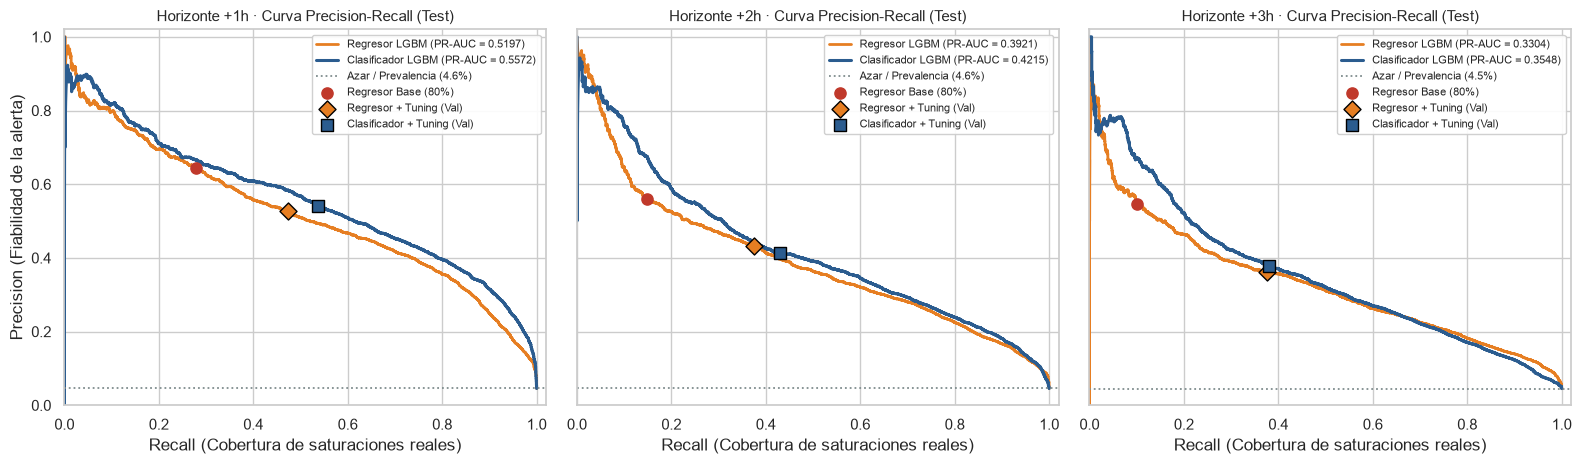

In [25]:
# ==============================================================================
# 5.2. CURVAS PRECISION-RECALL EN TEST: REGRESOR LGBM VS. CLASIFICADOR LGBM
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)

for idx, h in enumerate(HORIZONS_HOURS):
    ax = axes[idx]
    prec_reg, rec_reg, auc_reg = pr_curves_test[h]["reg"]
    prec_clf, rec_clf, auc_clf = pr_curves_test[h]["clf"]

    # Tasa base (prevalencia real de saturación en Test)
    base_rate = df_eval[f"real_sat_{h}h"].mean()

    ax.plot(
        rec_reg,
        prec_reg,
        color="#e67e22",
        linewidth=2.0,
        label=f"Regresor LGBM (PR-AUC = {auc_reg:.4f})",
    )
    ax.plot(
        rec_clf,
        prec_clf,
        color="#2b5c8f",
        linewidth=2.2,
        label=f"Clasificador LGBM (PR-AUC = {auc_clf:.4f})",
    )
    ax.axhline(
        base_rate,
        color="#7f8c8d",
        linestyle=":",
        linewidth=1.3,
        label=f"Azar / Prevalencia ({base_rate*100:.1f}%)",
    )

    # Puntos de operación elegidos en Validación
    sub_h = df_comp_s5.loc[f"+{h}h"]
    row_base = sub_h.iloc[0]
    row_tun = sub_h.iloc[1]
    row_clf = sub_h.iloc[2]

    ax.scatter(row_base["Recall"], row_base["Precision"], color="#c0392b", s=65, zorder=5, label="Regresor Base (80%)")
    ax.scatter(row_tun["Recall"], row_tun["Precision"], color="#e67e22", edgecolor="black", s=75, marker="D", zorder=6, label="Regresor + Tuning (Val)")
    ax.scatter(row_clf["Recall"], row_clf["Precision"], color="#2b5c8f", edgecolor="black", s=80, marker="s", zorder=6, label="Clasificador + Tuning (Val)")

    ax.set_title(f"Horizonte +{h}h · Curva Precision-Recall (Test)", fontsize=11)
    ax.set_xlabel("Recall (Cobertura de saturaciones reales)")
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.02)
    if idx == 0:
        ax.set_ylabel("Precision (Fiabilidad de la alerta)")
    ax.legend(loc="upper right", fontsize=8.0, framealpha=0.92)

plt.tight_layout()
plt.show()

### 5.3. Conclusiones del Prototipo y Veredicto Arquitectónico Final

La evaluación ciega sobre `Test` (con todos los umbrales calibrados estrictamente sobre `df_val` para garantizar cero *data leakage*) permite cerrar el diagnóstico de saturaciones con tres conclusiones definitivas:

1. **El *Threshold Tuning* captura la inmensa mayoría de la ganancia sin coste de arquitectura:**
   * Ajustando únicamente el umbral de decisión del regresor `LightGBM (Optuna)` sobre `df_val` (**74,0 %** en `+1h`, **70,0 %** en `+2h` y **65,0 %** en `+3h`), el **F1 Saturada** en `Test` mejora de forma sustancial:
     * **`+1h`:** de **0,3888** a **0,4985** (*Recall* de 27,86 % $\rightarrow$ 47,32 %; aciertos de 14.570 $\rightarrow$ 24.750 min).
     * **`+2h`:** de **0,2348** a **0,4018** (*Recall* de 14,86 % $\rightarrow$ 37,50 %; aciertos de 7.780 $\rightarrow$ 19.630 min).
     * **`+3h`:** de **0,1702** a **0,3694** (*Recall* de 10,08 % $\rightarrow$ 37,66 %; aciertos de 5.240 $\rightarrow$ 19.580 min).

2. **Mejora real pero marginal del clasificador binario (`LGBMClassifier`) en horizontes tácticos:**
   * El clasificador mejora la capacidad discriminativa global (**PR-AUC**) en los tres horizontes (**0,5572** vs. 0,5197 en `+1h`; **0,4215** vs. 0,3921 en `+2h`; **0,3548** vs. 0,3304 en `+3h`), destacando especialmente en la zona izquierda de las curvas PR (alta precisión con bajo *recall*).
   * Sin embargo, en el punto óptimo de operación por F1, su ventaja frente al *Regresor + Tuning* es moderada en `+1h` (**0,5387** vs. 0,4985) y muy reducida en los horizontes tácticos: **+0,0195 en `+2h`** (0,4213 vs. 0,4018, generando 6.320 min adicionales de FP) y apenas **+0,0095 en `+3h`** (0,3789 vs. 0,3694).

3. **Mejor calidad operativa de las falsas alarmas en el regresor:**
   * En los tres horizontes, los falsos positivos del **Regresor + Tuning** ocurren sobre estaciones con una ocupación real media superior (**65,46 %** en `+1h`, **62,79 %** en `+2h` y **60,92 %** en `+3h`) frente a los del clasificador (**61,76 %**, **57,97 %** y **56,82 %**). Esto reduce el riesgo operativo de enviar furgonetas a estaciones con carga intermedia.

---

### Decisión Final para Producción (`src/modeling/`)

Bajo un criterio de **coste-beneficio y parsimonia en producción**, se **descarta desplegar una arquitectura híbrida dual** (que obligaría a entrenar, versionar, testear y mantener 6 modelos en lugar de 3 por una ganancia inferior a 0,02 puntos de F1 en `+2h`/`+3h`).

La solución seleccionada para incorporar a `modelado_predictivo.ipynb` y `src/modeling/` consiste en:
* **Mantener los 3 regresores `LightGBM (Optuna)` actuales** como única fuente de predicción continua de ocupación ($\hat{y}_{s, t+h}$).
* **Incorporar la calibración automática de umbrales de alerta de saturación sobre `df_val`** (almacenados en `models/lgbm_v1/metadata.json` junto con el resto de trazabilidad), aplicando umbrales específicos por horizonte (~74 % en `+1h`, ~70 % en `+2h` y ~65 % en `+3h`) cuando se requieran alertas binarias de saturación.
* Dejar el **clasificador binario auxiliar** documentado como línea futura únicamente en caso de que el optimizador requiera operar en un régimen de muy alta precisión y volumen mínimo de alertas.